# Barridos con sustracción de fondo corregida

Las ventanas de resonancia se seleccionaron sobre los barridos crudos. Cada CSV
procesado guarda sus límites antes de la cabecera de datos.


In [31]:
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt

from Data import Sweep


In [32]:
def plot_amplitude_sweep(sweeps):
    """Plot the magnitude response for a collection of sweeps."""
    import numpy as np
    from matplotlib.colors import LinearSegmentedColormap

    plt.rcParams.update({
        "figure.figsize": (7.5, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 1.8,
        "legend.frameon": False,
        "figure.dpi": 100,
        "savefig.dpi": 500,
    })

    fig, ax = plt.subplots(layout="constrained")

    amplitudes = [sweep.amplitude for sweep in sweeps]
    norm = plt.Normalize(min(amplitudes), max(amplitudes))
    cmap = LinearSegmentedColormap.from_list(
        "magma",
        plt.colormaps["turbo"](np.linspace(0.0, 0.9, 256)),
    )

    for sweep in sweeps:
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)

        ax.plot(
            ff / 1e3, rr,
            color=cmap(norm(sweep.amplitude)),
            alpha=1,
        )

    ax.set_xlabel("Frecuencia excitación (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")

    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        label="Amplitud excitación (V)",
    )

    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax


def plot_both_ways(sweeps):
    """Plot a small selection of sweeps with a legend instead of a colorbar."""
    import numpy as np

    plt.rcParams.update({
        "figure.figsize": (6, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 3,
        "legend.frameon": False,
        "figure.dpi": 100,
        "savefig.dpi": 500,
        "legend.fontsize": 14,
        "legend.title_fontsize": 15,
    })

    fig, ax = plt.subplots(layout="constrained")
    color = plt.colormaps["Blues"](0.90)
    linestyles = ["--", "-"]

    for index, sweep in enumerate(sweeps):
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)
        ax.plot(
            ff / 1e3, rr,
            color=color,
            linestyle=linestyles[index % len(linestyles)],
            label=f"{sweep.amplitude:g} V",
        )

    ax.set_xlabel("Frecuencia excitaci\u00f3n (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")
    ax.legend(title="Amplitud excitaci\u00f3n (V)")
    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax


def plot_high_voltage_sweeps(sweeps, directions):
    """Plot high-voltage sweeps with one color per excitation voltage."""
    import numpy as np

    plt.rcParams.update({
        "figure.figsize": (7.5, 5),
        "font.family": "sans-serif",
        "font.size": 20,
        "axes.labelsize": "medium",
        "axes.linewidth": 1.8,
        "axes.grid": False,
        "xtick.labelsize": "medium",
        "ytick.labelsize": "medium",
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 7,
        "ytick.major.size": 7,
        "xtick.major.width": 1.2,
        "ytick.major.width": 1.2,
        "lines.linewidth": 2,
        "legend.frameon": False,
        "legend.fontsize": 14,
        "legend.title_fontsize": 15,
        "figure.dpi": 100,
        "savefig.dpi": 500,
    })

    fig, ax = plt.subplots(layout="constrained")
    colors = plt.colormaps["Dark2"].colors
    labeled_amplitudes = set()

    for sweep, direction in zip(sweeps, directions):
        ff, xx, yy = np.array(sweep.data).T
        rr = np.hypot(xx, yy)
        label = (
            f"{sweep.amplitude:g} V"
            if sweep.amplitude not in labeled_amplitudes
            else "_nolegend_"
        )
        labeled_amplitudes.add(sweep.amplitude)
        ax.plot(
            ff / 1e3, rr,
            color=color_by_amplitude[sweep.amplitude],
            linestyle="--" if direction == "backward" else "-",
            label=label,
        )

    ax.set_xlabel("Frecuencia excitaci\u00f3n (kHz)")
    ax.set_ylabel("Amplitud resonador (V)")
    ax.legend(title="Amplitud excitaci\u00f3n (V)")
    ax.ticklabel_format(
        axis="y", style="sci", scilimits=(0, 0), useMathText=True,
    )

    return fig, ax



def plot_high_voltage_separated(sweeps, excitation_labels):
    """Plot high-voltage sweeps on separate y axes with a shared x axis."""
    import numpy as np
    from matplotlib.ticker import MaxNLocator

    if len(sweeps) != len(excitation_labels):
        raise ValueError(
            "Debe haber una etiqueta de excitación por cada barrido."
        )

    figure_size = (7, 9)
    font_size = 20
    blue = plt.colormaps["Blues"](0.75)

    fig, axes = plt.subplots(
        nrows=len(sweeps),
        ncols=1,
        sharex=True,
        figsize=figure_size,
        layout="constrained",
    )
    axes = np.atleast_1d(axes)

    for ax, sweep, excitation_label in zip(
        axes,
        sweeps,
        excitation_labels,
    ):
        frequency, x_signal, y_signal = np.array(sweep.data).T
        amplitude = np.hypot(x_signal, y_signal)
        ax.plot(frequency / 1e3, amplitude, color=blue)
        ax.set_ylim(
            bottom=0,
            top=1.28 * np.max(amplitude),
        )
        ax.tick_params(axis="both", labelsize=font_size)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.ticklabel_format(
            axis="y", style="sci", scilimits=(0, 0), useMathText=True,
        )
        ax.yaxis.get_offset_text().set_fontsize(font_size)
        ax.text(
            0.97,
            0.94,
            f"Excitación: {excitation_label}",
            transform=ax.transAxes,
            fontsize=font_size,
            ha="right",
            va="top",
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
                "pad": 2,
            },
        )
        ax.grid(False)

    fig.supylabel(
        "Amplitud resonador (V)",
        fontsize=font_size,
    )
    axes[-1].set_xlabel(
        "Frecuencia excitación (kHz)",
        fontsize=font_size,
        labelpad=8,
    )
    fig.set_constrained_layout_pads(
        w_pad=0.08,
        h_pad=0.08,
        hspace=0.05,
    )

    return fig, axes


In [33]:
# Corrección de barridos


windows = {
    # "26-10-1507": (64700, 66600),
    # "26-10-1522": (64750, 65300),
    "26-10-1644": (64550, 64750),
    "26-10-1651": (64400, 64800),
    "26-10-1657": (64400, 64800),
    "26-10-1704": (64400, 64950),
    "26-10-1711": (64350, 65250),
    "26-10-1717": (64300, 65550),
    "26-10-1724": (64250, 65650),
    "26-10-1730": (64250, 65900),
    "26-10-1737": (64200, 66100),
    "26-10-1744": (64200, 66450),
    "26-10-1750": (64200, 66800),
    "26-10-1757": (64150, 67200),
}
source_folder = Path("Mediciones/Barrido_Amplitudes")
output_folder = source_folder / "mediciones_sin_fondo_corregida"
raw_files = sorted(source_folder.glob("*.csv"))

# Desde el barrido 26-10-1812 la ventana es la misma para todos.
for file in raw_files[12:]:
    windows[file.stem] = (64150, 67450)

output_folder.mkdir(parents=True, exist_ok=True)

for file in raw_files:
    sweep = Sweep(file)
    corrected = sweep.subtract_background(windows[file.stem])
    corrected.save(output_folder / f"{file.stem}_SF.csv")

print(f"Se generaron {len(raw_files)} barridos corregidos")


Se generaron 84 barridos corregidos


[Text(0.5, 0, 'Amplitud excitación (V)'),
 Text(0, 0.5, 'Frecuencia de corte (kHz)')]

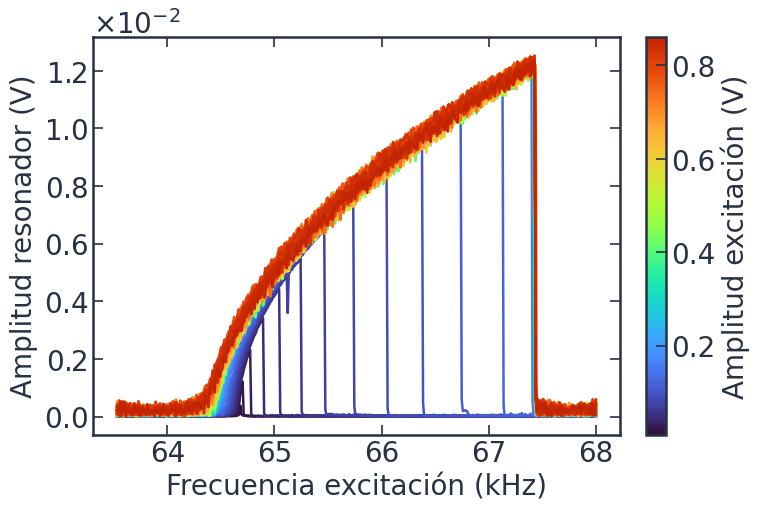

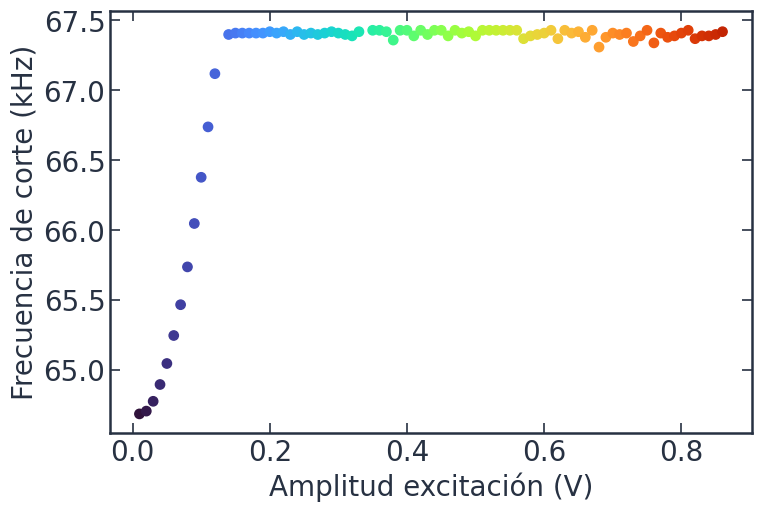

In [34]:
%matplotlib inline
sweeps = [Sweep(file) for file in sorted(output_folder.glob("*_SF.csv"))]

fig, ax = plot_amplitude_sweep(sweeps)

fig.savefig(
    r"C:\Main\Drive\Facultad\Materias\Experimental III\Figuras\barridos_amplitud.png",
)

import numpy as np
from matplotlib.colors import LinearSegmentedColormap

amplitudes = np.array([sweep.amplitude for sweep in sweeps])
cutoff_frequencies = np.array([
    frequency[np.argmax(np.hypot(x_signal, y_signal))]
    for frequency, x_signal, y_signal in (np.array(sweep.data).T for sweep in sweeps)
])
norm = plt.Normalize(amplitudes.min(), amplitudes.max())
cmap = LinearSegmentedColormap.from_list(
    "turbo_truncated", plt.colormaps["turbo"](np.linspace(0.0, 0.9, 256)),
)

fig_cutoff, ax_cutoff = plt.subplots(layout="constrained")
ax_cutoff.scatter(amplitudes, cutoff_frequencies / 1e3, c=cmap(norm(amplitudes)), s=45)
ax_cutoff.set(
    xlabel="Amplitud excitación (V)",
    ylabel="Frecuencia de corte (kHz)",
)


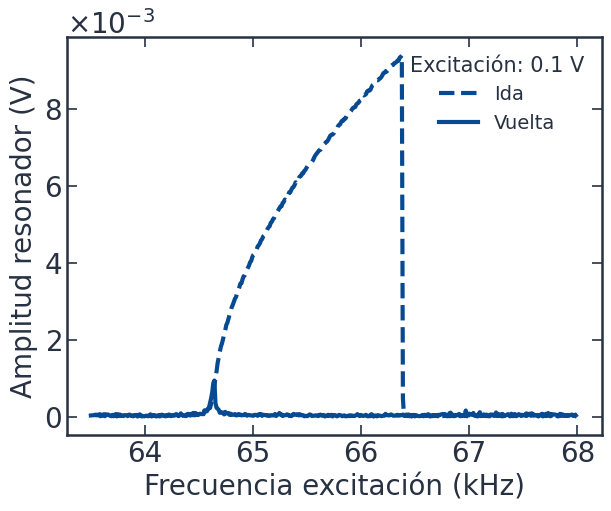

In [35]:
%matplotlib inline
ida_y_vuelta_folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Ida_y_Vuelta")
ida_y_vuelta_file = next(ida_y_vuelta_folder.glob("*.csv"))
ida_y_vuelta_sweep = Sweep(ida_y_vuelta_file)
forward_window = (64500, 66400)
backward_window = (64500, 66400)
ida_y_vuelta_corrected = ida_y_vuelta_sweep.subtract_background_bidirectional(
    forward_window, backward_window
)
fig_ida_y_vuelta, ax_ida_y_vuelta = plot_both_ways(ida_y_vuelta_corrected)
ax_ida_y_vuelta.lines[0].set_label("Ida")
ax_ida_y_vuelta.lines[1].set_label("Vuelta")
ax_ida_y_vuelta.legend(
    title=f"Excitaci\u00f3n: {ida_y_vuelta_sweep.amplitude:g} V"
)
fig_ida_y_vuelta.savefig(
    ida_y_vuelta_folder / "ida_y_vuelta_corregida.png",
    dpi=500,
    bbox_inches="tight",
)
plt.show()


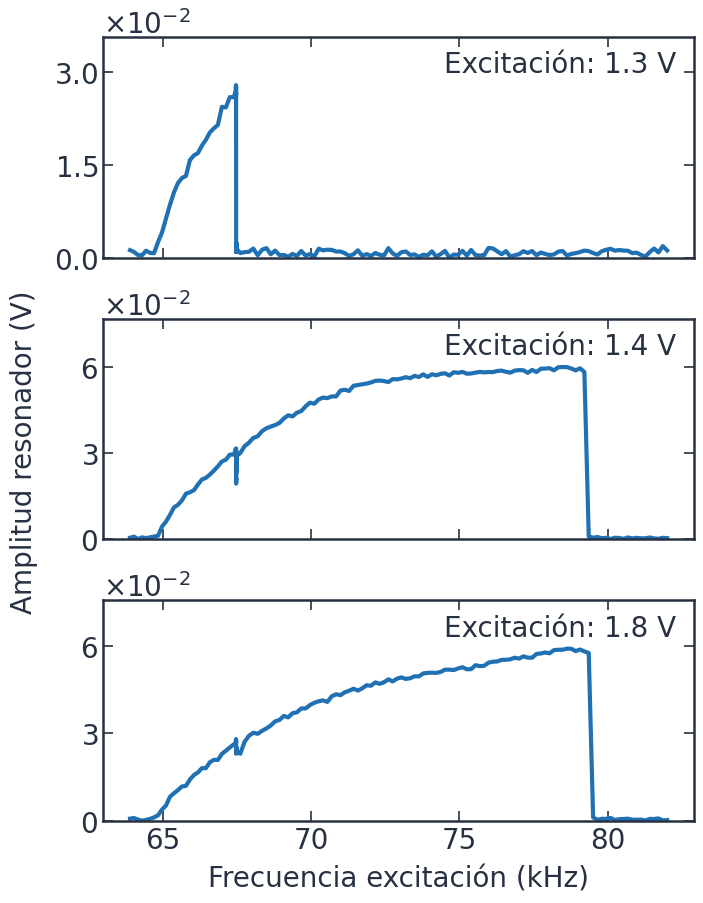

In [36]:
%matplotlib inline
from importlib import reload
from pathlib import Path

import Data
import numpy as np

Data = reload(Data)
Sweep = Data.Sweep

alto_voltaje_folder = Path(
    r"C:\Main\Repos\MEMS\Mediciones\alto voltaje"
)
correction_parameters = {
    "1.3v_1": ((64500, 67500), 4),
    "1.4v_1": ((64500, 79400), 4),
    "1.8v_1": ((64500, 79400), 4),
}
corrected_sweeps = []

for folder, (resonance_window, degree) in correction_parameters.items():
    forward_parts = []

    for file in sorted((alto_voltaje_folder / folder).glob("*.csv")):
        sweep = Sweep(file)
        frequencies = np.array(
            [frequency for frequency, _, _ in sweep.data]
        )

        if np.any(np.diff(frequencies) < 0):
            sweep, _ = sweep.split_bidirectional()

        forward_parts.append(sweep)

    forward = Sweep.stitch(forward_parts)
    corrected_sweeps.append(
        forward.subtract_background(resonance_window, degree=degree)
    )

fig_separated, axes_separated = plot_high_voltage_separated(
    corrected_sweeps,
    ("1.3 V", "1.4 V", "1.8 V"),
)
fig_separated.savefig(
    alto_voltaje_folder / "alto_voltaje_corregido_ejes_separados.png",
    dpi=500,
    bbox_inches="tight",
)
plt.show()


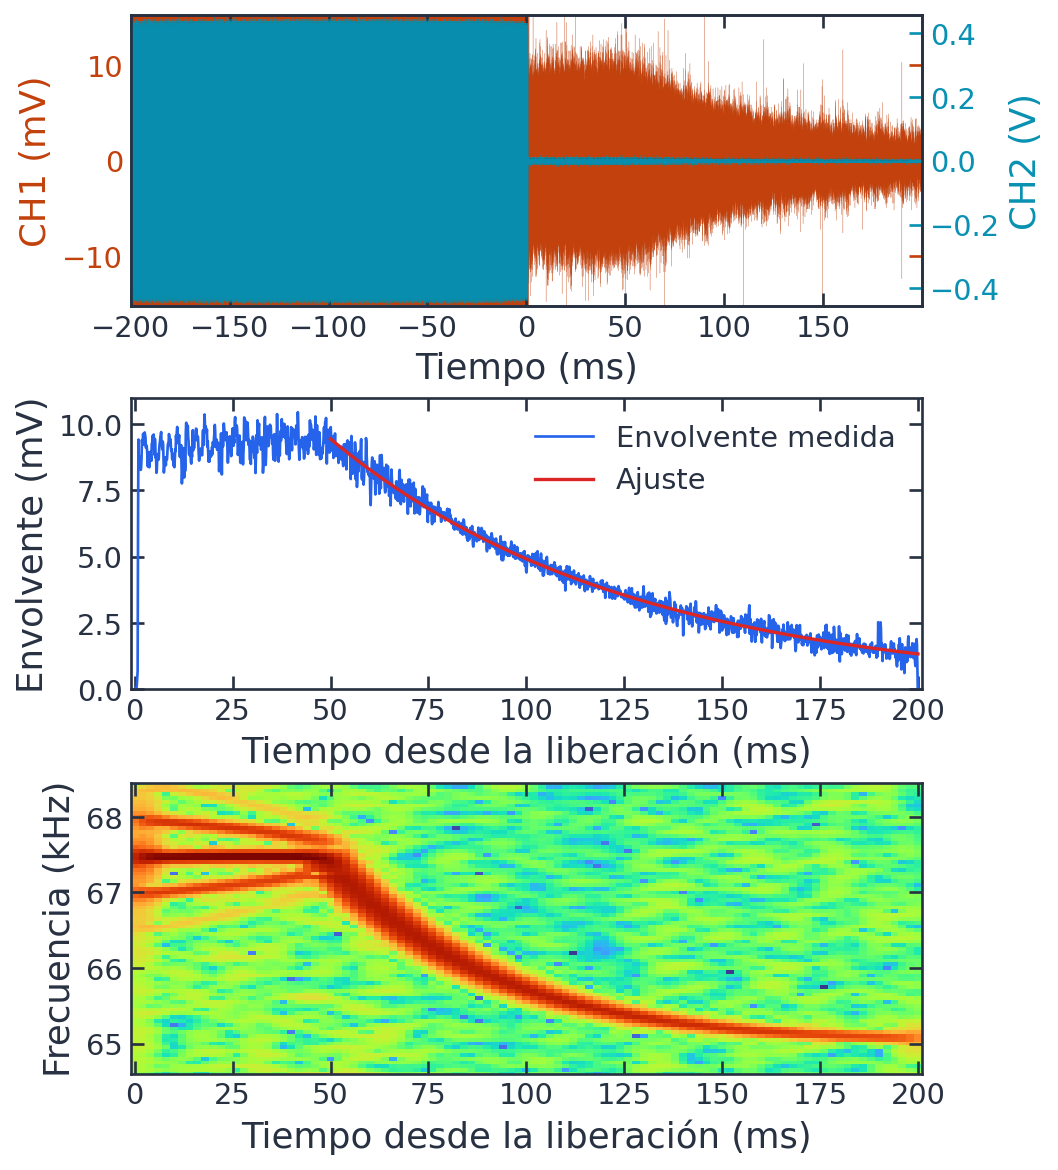

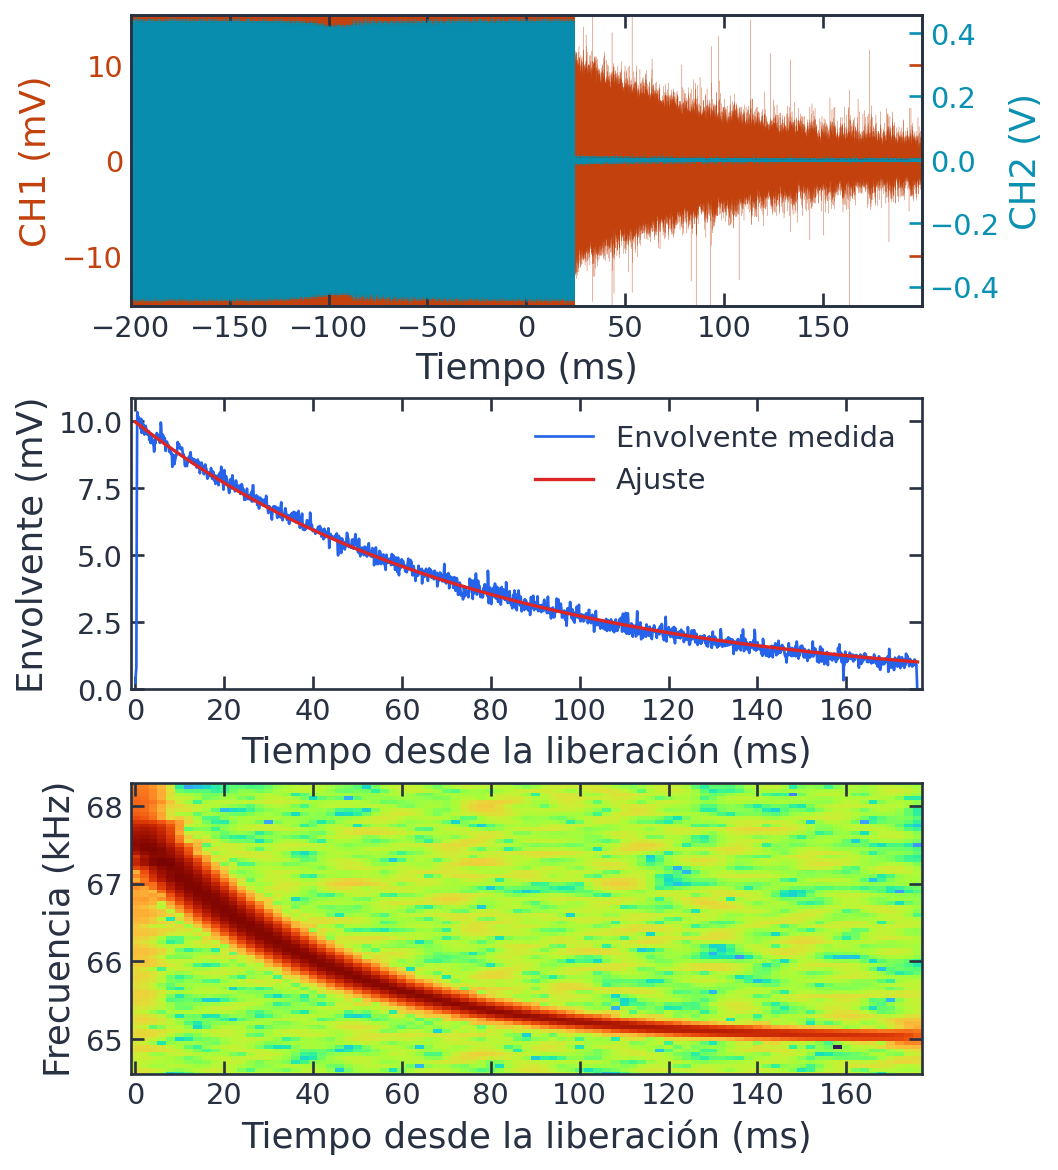

In [37]:
from pathlib import Path
from Data import Ringdown
ringdown_1625 = Ringdown(Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11\ringdown-02-11-1625.csv"))
ringdown_1637 = Ringdown(Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11\ringdown-02-11-1637.csv"))
for ringdown, release_time, decay_start_time in ((ringdown_1625, 0, 0.05), (ringdown_1637, 0.024, 0)):
    ringdown.reconstruct(release_time).analyze((63e3, 70e3), decay_start_time=decay_start_time, noise_bands=((60e3, 63e3), (70e3, 75e3))).plot();


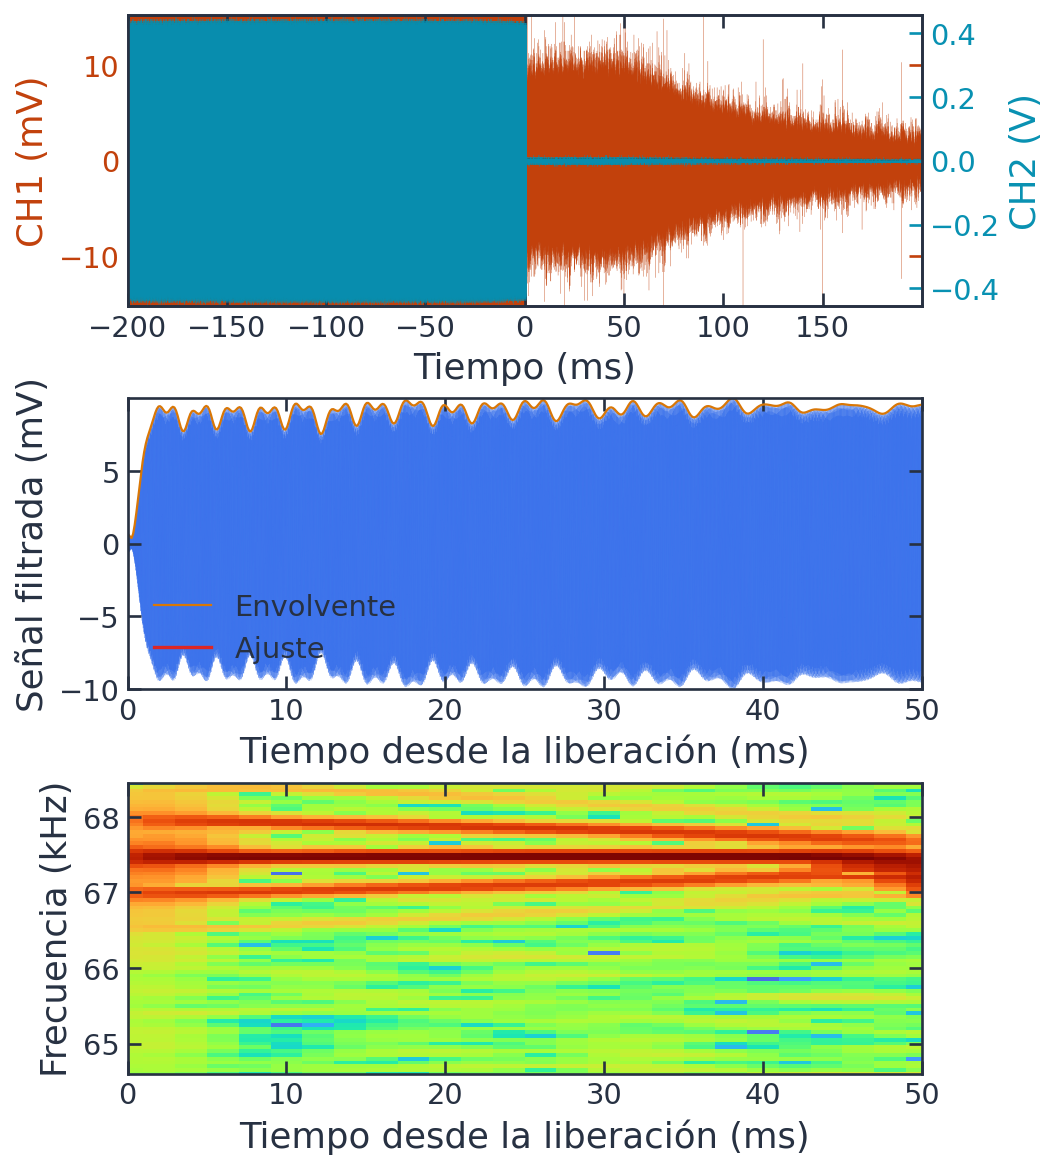

In [38]:
# Vista de 0 a 70 ms con la portadora y ambas sidebands.
ringdown_1625.plot(filtered_band=(66.9e3, 68.1e3), time_limits=(0, 0.05));


In [39]:
import numpy as np
from scipy.optimize import curve_fit
sweep_5111825 = Sweep(Path(r"C:\Main\Repos\MEMS\05-11-1825.csv"))
window_5111825 = (65060, 65150)
corrected_5111825 = sweep_5111825.subtract_background(window_5111825)
frequency, x_signal, y_signal = np.array(corrected_5111825.data).T
amplitude = np.hypot(x_signal, y_signal)
plot_mask = frequency <= window_5111825[1]
fit_mask = (frequency >= window_5111825[0]) & (frequency <= window_5111825[1])
lorentzian = lambda f, offset, height, center, half_width: offset + height / np.sqrt(1 + ((f - center) / half_width) ** 2)
parameters, _ = curve_fit(lorentzian, frequency[fit_mask], amplitude[fit_mask], p0=(np.median(amplitude[~fit_mask]), amplitude[fit_mask].max(), frequency[fit_mask][amplitude[fit_mask].argmax()], 3), bounds=([-np.inf, 0, window_5111825[0], 0], [np.inf, np.inf, window_5111825[1], np.inf]))
print(f"Frecuencia del modo pandeo: {parameters[2] / 1e3:.4f} kHz")
print(f"Factor de calidad: {parameters[2] / (2 * parameters[3]):.0f}")


Frecuencia del modo pandeo: 65.0764 kHz
Factor de calidad: 21129


In [40]:
q_sweep = parameters[2] / (2 * parameters[3])
q_ringdown = {"16:25": np.pi * parameters[2] / ringdown_1625.damping, "16:37": np.pi * parameters[2] / ringdown_1637.damping}
peak_frequencies = [np.array(sweep.data).T[0][np.argmax(np.hypot(*np.array(sweep.data).T[1:]))] for sweep in sweeps]
mode_1_ri_frequency = np.median(peak_frequencies)
mode_3_frequency = 3 * mode_1_ri_frequency
print(f"Q del barrido: {q_sweep:.0f}")
print("Q de ringdown:", {name: f"{value:.0f}" for name, value in q_ringdown.items()})
print(f"Frecuencia modo 1 lineal: {parameters[2] / 1e3:.3f} kHz")
print(f"Frecuencia modo 1 RI: {mode_1_ri_frequency / 1e3:.3f} kHz")
print(f"Frecuencia modo 3: {mode_3_frequency / 1e3:.3f} kHz")


Q del barrido: 21129
Q de ringdown: {'16:25': '15678', '16:37': '15801'}
Frecuencia modo 1 lineal: 65.076 kHz
Frecuencia modo 1 RI: 67.409 kHz
Frecuencia modo 3: 202.226 kHz


In [41]:
# Estilo común para las figuras de paper.
from pathlib import Path
# Requires collint==0.1.1 in the notebook kernel.
from collint import check as collint_check
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
PAPER_OUTPUT_DIR = Path(r'C:\Main\Repos\MEMS\Figuras_paper')
PAPER_OUTPUT_DIR.mkdir(exist_ok=True)
MM = 1 / 25.4
PAPER_STYLE = {'font.family':'serif', 'font.serif':['STIX Two Text','STIXGeneral','DejaVu Serif'], 'mathtext.fontset':'stix', 'font.size':9.5, 'axes.labelsize':10, 'axes.linewidth':1.25, 'axes.grid':False, 'axes.facecolor':'white', 'figure.facecolor':'white', 'savefig.facecolor':'white', 'savefig.transparent':False, 'xtick.labelsize':9.5, 'ytick.labelsize':9.5, 'xtick.direction':'in', 'ytick.direction':'in', 'xtick.major.size':4.5, 'ytick.major.size':4.5, 'xtick.minor.size':2.3, 'ytick.minor.size':2.3, 'xtick.major.width':1.1, 'ytick.major.width':1.1, 'legend.fontsize':9, 'legend.frameon':False, 'pdf.fonttype':42, 'ps.fonttype':42, 'savefig.bbox':'tight', 'savefig.pad_inches':.03}
INK, ACCENT, FIT, MUTED = '#252A2D', '#24527A', '#9F3E29', '#B6C0C2'
SELECTED_COLORS = ('#0B4458', '#0F678B', '#13A598', '#C04931')  # Reference swatches, left to right
POWER_CMAP = LinearSegmentedColormap.from_list('paper_power', ['#D8E5E2', '#90B9BD', '#D08C63', '#AD5240', '#712D3D'])
def style_paper_axis(ax, *, image=False):
    if not image:
        ax.spines[['top','right']].set_visible(False)
    ax.tick_params(which='both', top=False, right=False, colors=INK)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.set_xlabel(ax.get_xlabel(), color=INK)
    ax.set_ylabel(ax.get_ylabel(), color=INK)
    return ax


COLLINT_ACTIONABLE = {}

def review_with_collint(fig, figure_name):
    # Matplotlib keeps inset axes in parent.child_axes; collint checks fig.axes.
    parent_child = []
    def register_children(parent):
        for child in parent.child_axes:
            fig.add_axes(child)
            parent_child.append((parent, child))
            register_children(child)
    for parent in list(fig.axes):
        register_children(parent)
    axis_ids = {axis: f'axes{index}' for index, axis in enumerate(fig.axes)}
    try:
        report = collint_check(fig)
    finally:
        for _, child in reversed(parent_child):
            fig.delaxes(child)

    def expected_overlap(item):
        if item.kind == 'clipping' and item.a_role == 'data-artist' and item.b_role == 'clip':
            return True  # Data outside the displayed range are clipped by the axes.
        for parent, child in parent_child:
            parent_id, child_id = axis_ids[parent], axis_ids[child]
            if (item.kind == 'element_element' and item.a_role == item.b_role == 'axes-region'
                    and {item.a_id, item.b_id} == {parent_id, child_id}):
                return True  # An inset intentionally occupies its parent's axes region.
            if (item.kind == 'over_data' and item.a_role in ('legend', 'annotation')
                    and item.b_role == 'data-artist'
                    and item.a_id.startswith(child_id + '.')
                    and item.b_id.startswith(parent_id + '.')
                    and child.patch.get_facecolor()[3] >= .99):
                x0, y0, x1, y1 = item.a_box
                box = child.bbox
                if x0 >= box.x0 and y0 >= box.y0 and x1 <= box.x1 and y1 <= box.y1:
                    return True  # Opaque inset hides the parent's data beneath it.
        return False

    actionable = [item for item in report.collisions if not expected_overlap(item)]
    COLLINT_ACTIONABLE[figure_name] = actionable
    ignored = len(report.collisions) - len(actionable)
    print(
        f'{figure_name}: collint '
        f'actionable collisions={len(actionable)}; '
        f'intentional overlaps ignored={ignored}'
    )
    for item in actionable:
        print(
            f'  {item.kind}: {item.a_role} ({item.a_id}) / '
            f'{item.b_role} ({item.b_id}), severity={item.severity:.3g}'
        )
    return report


figure_1_amplitude_sweeps: collint actionable collisions=0; intentional overlaps ignored=89


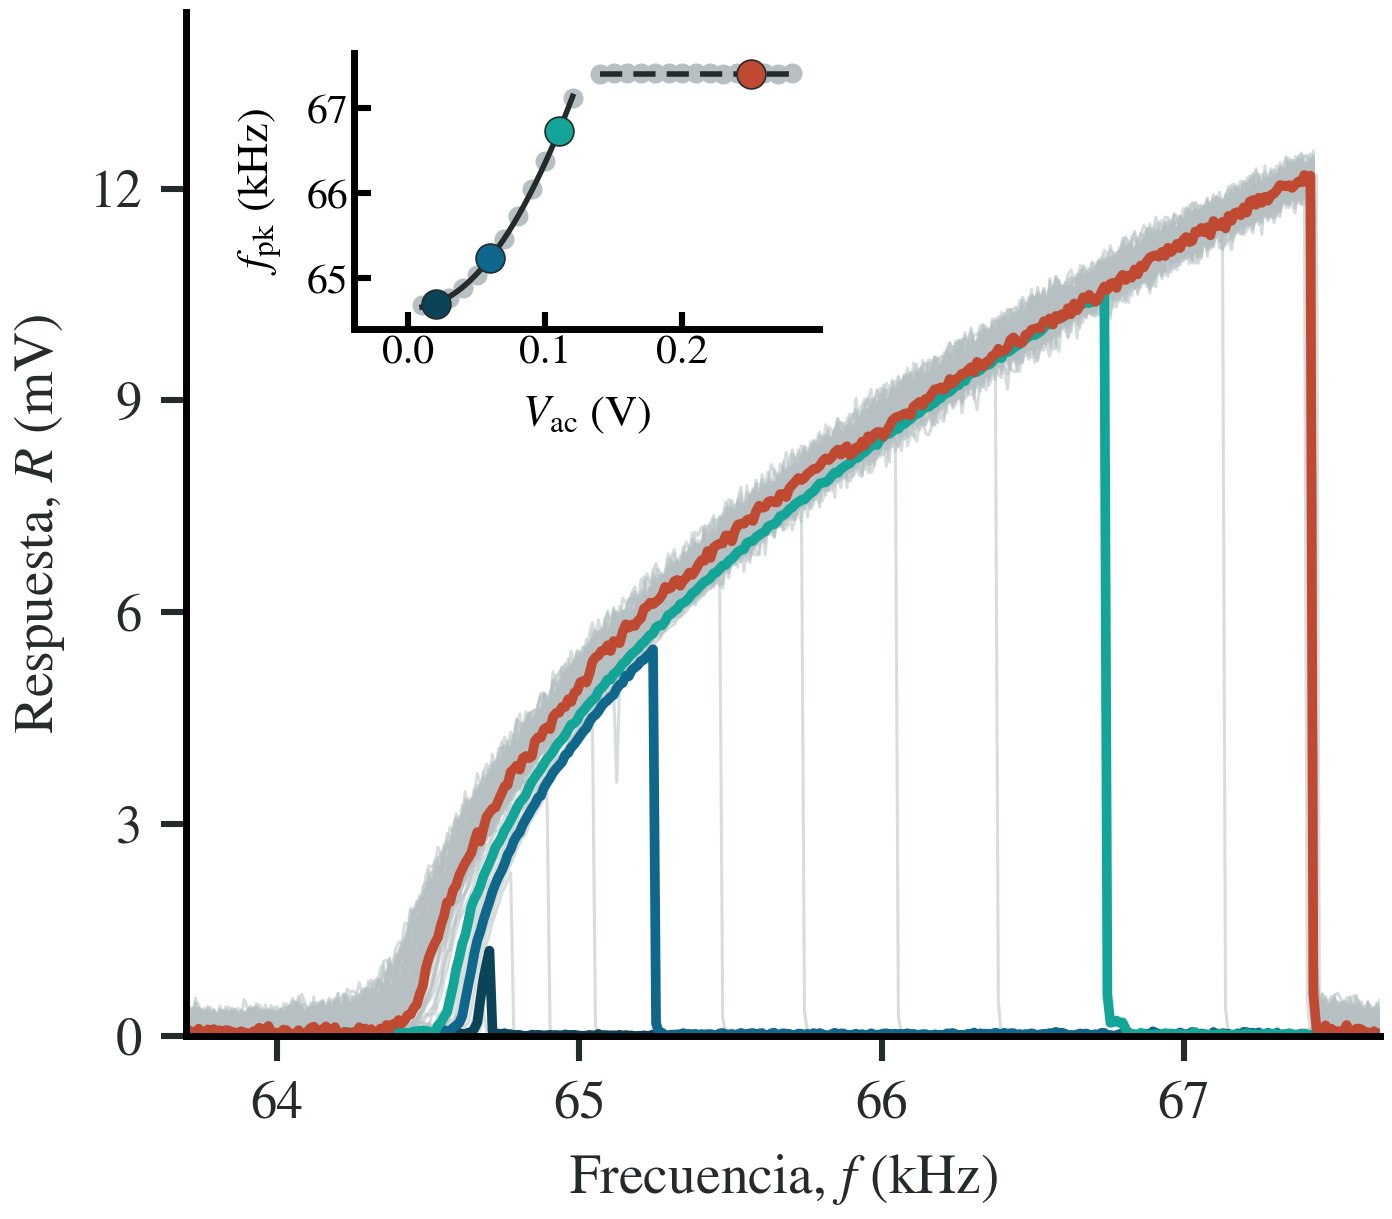

In [42]:
# Los 84 barridos originales y un unico inset lineal para la frecuencia de pico.
vac = amplitudes
peak_frequency = cutoff_frequencies
with mpl.rc_context(PAPER_STYLE):
    fig_amplitude, ax_amplitude = plt.subplots(figsize=(89*MM,78*MM), layout='constrained')
    selected_targets = (.02, .06, .11, .25)
    selected_indices = [int(np.argmin(np.abs(vac-target))) for target in selected_targets]
    for sweep in sweeps:
        f, x, y = np.asarray(sweep.data).T
        ax_amplitude.plot(f*1e-3, np.hypot(x,y)*1e3, color=MUTED, lw=.55, alpha=.55)
    for idx, color in zip(selected_indices, SELECTED_COLORS):
        f, x, y = np.asarray(sweeps[idx].data).T
        ax_amplitude.plot(f*1e-3, np.hypot(x,y)*1e3, color=color, lw=1.75)
    ax_amplitude.set(xlabel=r'Frecuencia, $f$ (kHz)', ylabel=r'Respuesta, $R$ (mV)', xlim=(63.7,67.65), ylim=(0,14.5))
    style_paper_axis(ax_amplitude)
    ax_amplitude.tick_params(which='both', direction='out')
    ax_amplitude.set_xticks([64,65,66,67]); ax_amplitude.set_yticks([0,3,6,9,12])
    quadratic_mask = vac <= .12
    plateau_mask = vac >= .14
    quadratic_fit = np.polyfit(vac[quadratic_mask], peak_frequency[quadratic_mask]*1e-3, 2)
    plateau_fit = np.polyfit(vac[plateau_mask], peak_frequency[plateau_mask]*1e-3, 0)[0]
    v_quadratic = np.linspace(vac[quadratic_mask].min(), vac[quadratic_mask].max(), 100)
    v_plateau = np.linspace(vac[plateau_mask].min(), .28, 100)
    ax_peak = ax_amplitude.inset_axes([.14,.69,.39,.27])
    ax_peak.set_facecolor('white')
    ax_peak.plot(v_quadratic, np.polyval(quadratic_fit,v_quadratic), color=INK, lw=1.0, label='Cuadrática', zorder=3)
    ax_peak.plot(v_plateau, np.full_like(v_plateau,plateau_fit), color=INK, lw=1.0, ls=(0,(4,2)), label='Constante', zorder=3)
    detail_mask = vac <= .28
    ax_peak.scatter(vac[detail_mask], peak_frequency[detail_mask]*1e-3, color=MUTED, s=13, linewidths=0, zorder=2)
    for idx, color in zip(selected_indices, SELECTED_COLORS):
        ax_peak.scatter(vac[idx], peak_frequency[idx]*1e-3, color=color, edgecolors=INK, linewidths=.3, s=27, zorder=4)
    ax_peak.set(xlabel=r'$V_\mathrm{ac}$ (V)', ylabel=r'$f_\mathrm{pk}$ (kHz)', xlim=(-.04,.30), ylim=(64.4,67.65))
    ax_peak.text(.18,66.48,'67,4 kHz',color=INK,fontsize=5.8,ha='left',va='center',zorder=5)
    ax_peak.spines[['top','right']].set_visible(False)
    ax_peak.set_xticks([0,.1,.2]); ax_peak.set_yticks([65,66,67])
    ax_peak.tick_params(labelsize=7.5, length=3, pad=1, direction='in', top=False, right=False)
    ax_peak.xaxis.label.set_size(8); ax_peak.yaxis.label.set_size(8)
    collint_result = review_with_collint(fig_amplitude, 'figure_1_amplitude_sweeps')
    fig_amplitude.savefig(PAPER_OUTPUT_DIR/'figure_1_amplitude_sweeps.pdf')
    fig_amplitude.savefig(PAPER_OUTPUT_DIR/'figure_1_amplitude_sweeps.png',dpi=400)


figure_2_hysteresis: collint actionable collisions=0; intentional overlaps ignored=2


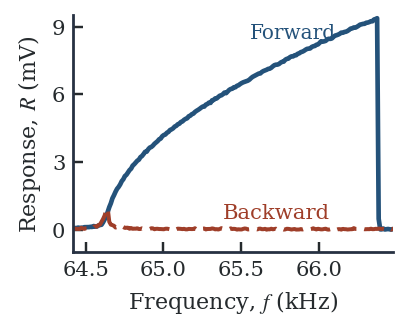

In [43]:
# Las dos ramas corregidas son las de la celda original.
# Ancho final en el paper: 72 mm. Conservar este ancho al insertarla.
forward, backward = ida_y_vuelta_corrected

with mpl.rc_context(PAPER_STYLE):
    fig_hysteresis, ax_hysteresis = plt.subplots(
        figsize=(62 * MM, 58 * MM), layout='constrained'
    )

    for sweep, ls, color, lw in (
        (forward, '-', ACCENT, 2.1),
        (backward, (0, (5, 2)), FIT, 1.8),
    ):
        f, x, y = np.asarray(sweep.data).T
        ax_hysteresis.plot(
            f * 1e-3, np.hypot(x, y) * 1e3,
            color=color, ls=ls, lw=lw
        )

    ax_hysteresis.set(
        xlabel=r'Frequency, $f$ (kHz)',
        ylabel=r'Response, $R$ (mV)',
        xlim=(64.42, 66.48),
        ylim=(-1, 9.5)
    )
    style_paper_axis(ax_hysteresis)
    ax_hysteresis.set_box_aspect(.74)
    ax_hysteresis.set_yticks([0, 3, 6, 9])
    ax_hysteresis.text(65.56, 8.50, 'Forward', color=ACCENT, fontsize=9)
    ax_hysteresis.text(65.38, .48, 'Backward', color=FIT, fontsize=9.5)

    collint_result = review_with_collint(fig_hysteresis, 'figure_2_hysteresis')
    fig_hysteresis.savefig(PAPER_OUTPUT_DIR / 'figure_2_hysteresis.pdf')
    fig_hysteresis.savefig(PAPER_OUTPUT_DIR / 'figure_2_hysteresis.png', dpi=400)

figure_lorentzian: collint actionable collisions=0; intentional overlaps ignored=0


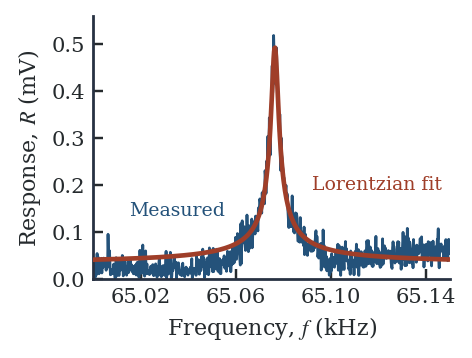

In [44]:
# El barrido corregido y los parámetros son los de la celda de análisis.
# Ancho final en el paper: 72 mm. Conservar este ancho al insertarla.
with mpl.rc_context(PAPER_STYLE):
    fig_lorentzian, ax_lorentzian = plt.subplots(figsize=(72*MM,58*MM), layout='constrained')
    f_khz = frequency[plot_mask] * 1e-3
    response_mv = amplitude[plot_mask] * 1e3
    fit_mv = lorentzian(frequency[plot_mask], *parameters) * 1e3
    ax_lorentzian.plot(f_khz, response_mv, color=ACCENT, lw=1.25, label='Measured')
    ax_lorentzian.plot(f_khz, fit_mv, color=FIT, lw=2.1, label='Lorentzian fit', zorder=3)
    ax_lorentzian.set(xlabel=r'Frequency, $f$ (kHz)', ylabel=r'Response, $R$ (mV)', xlim=(65.00,65.15), ylim=(0,.56))
    style_paper_axis(ax_lorentzian)
    ax_lorentzian.set_box_aspect(.74)
    ax_lorentzian.set_xticks([65.02,65.06,65.10,65.14])
    ax_lorentzian.set_yticks([0,.1,.2,.3,.4,.5])
    ax_lorentzian.text(65.015, .135, 'Measured', color=ACCENT, fontsize=8.5)
    ax_lorentzian.text(65.092, .19, 'Lorentzian fit', color=FIT, fontsize=8.5)
    collint_result = review_with_collint(fig_lorentzian, 'figure_lorentzian')
    fig_lorentzian.savefig(PAPER_OUTPUT_DIR/'figure_lorentzian.pdf')
    fig_lorentzian.savefig(PAPER_OUTPUT_DIR/'figure_lorentzian.png', dpi=400)


figure_2_lorentzian_hysteresis: collint actionable collisions=0; intentional overlaps ignored=2


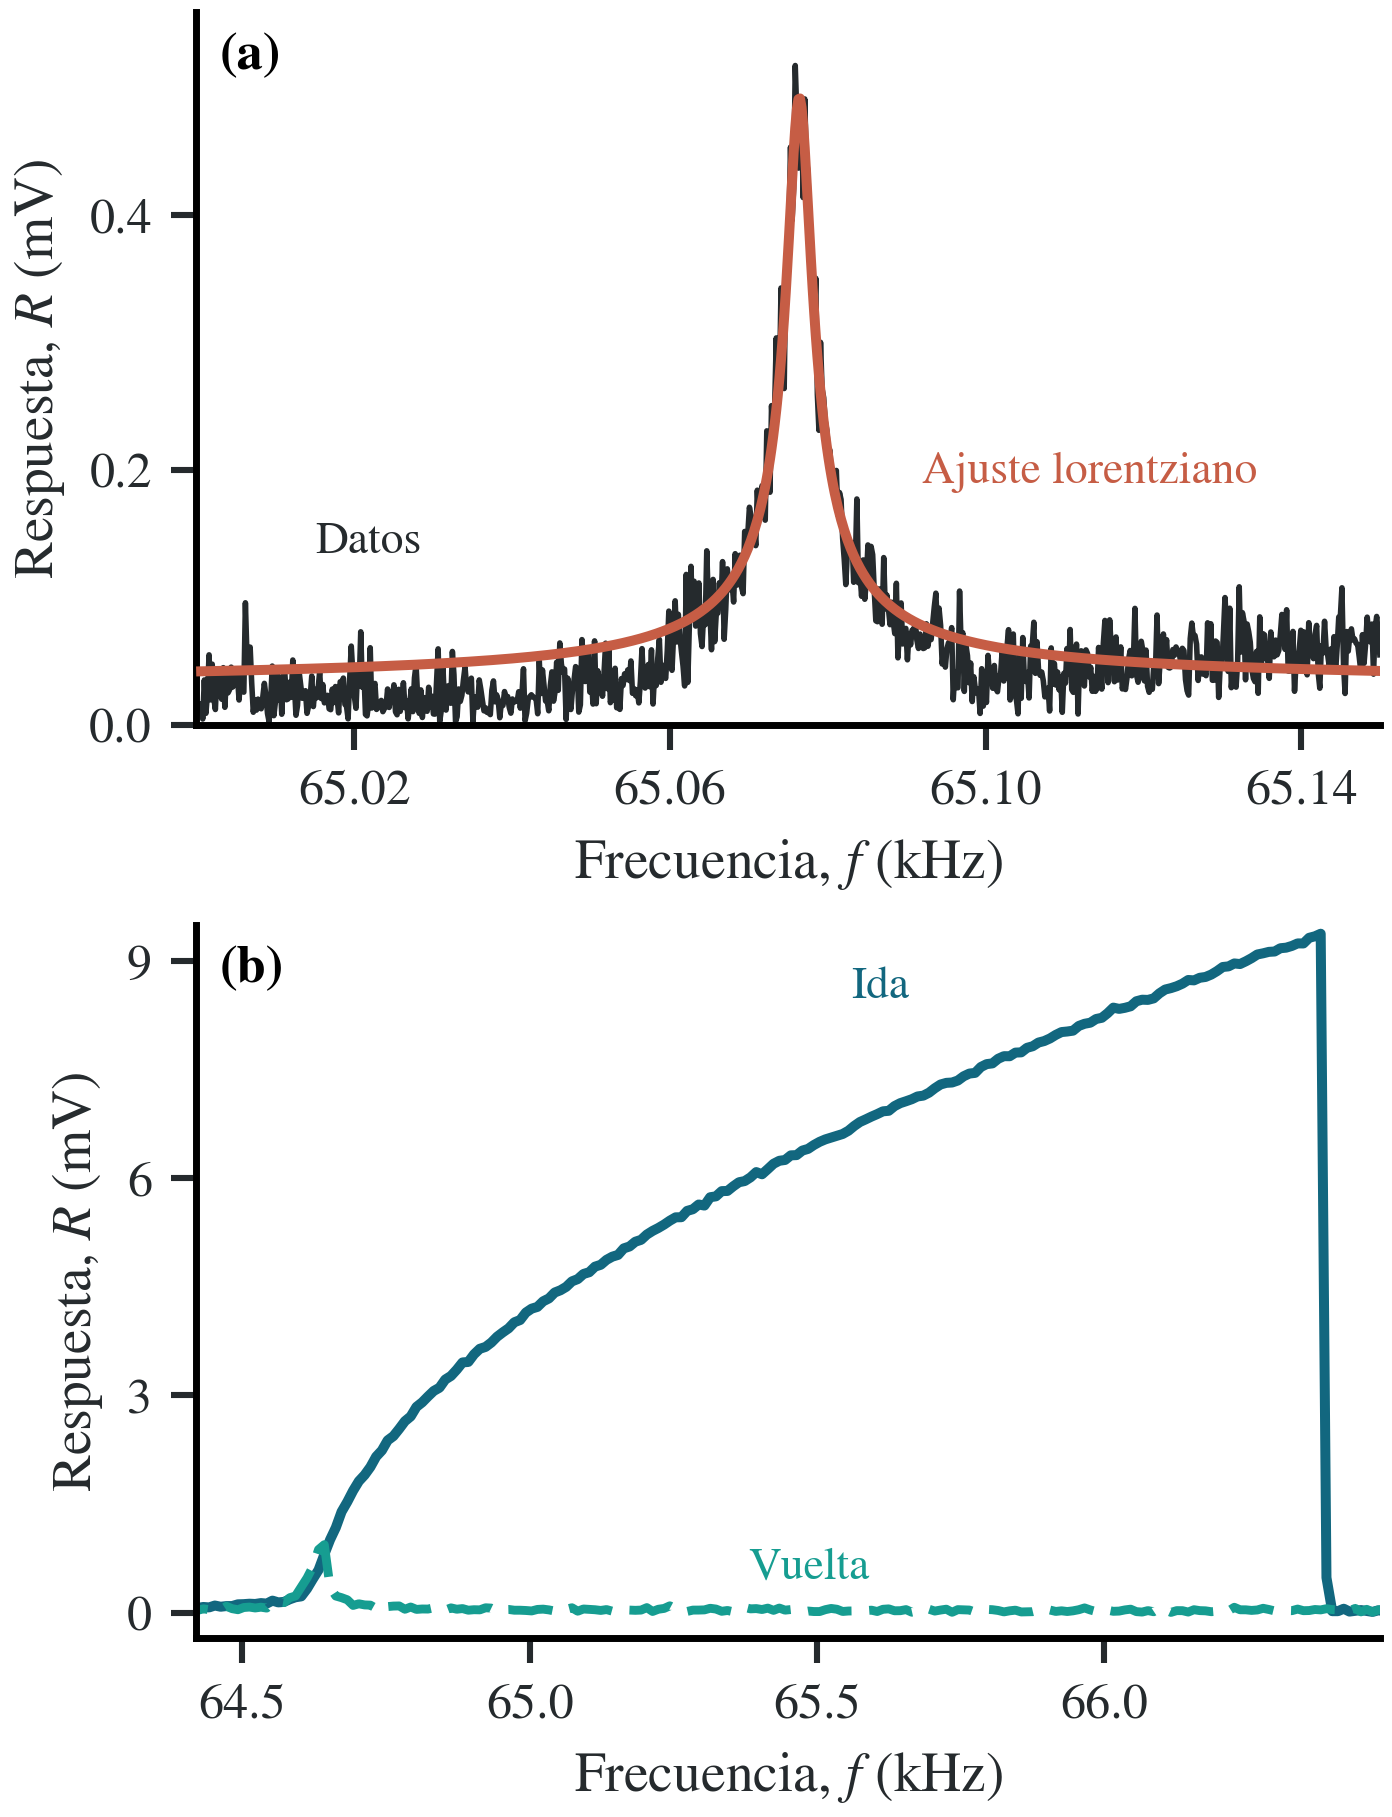

In [45]:
# Resonancia lorentziana y ramas de histéresis en dos paneles.
fit_color = '#C65D45'
forward_color = '#003B70'
backward_color = '#B64700'
with mpl.rc_context(PAPER_STYLE):
    fig_lorentzian_hysteresis, (ax_lorentzian, ax_hysteresis) = plt.subplots(
        nrows=2, ncols=1, figsize=(89*MM,116*MM), layout='constrained',
        gridspec_kw={'height_ratios': [1, 1]},
    )

    f_khz = frequency[plot_mask] * 1e-3
    response_mv = amplitude[plot_mask] * 1e3
    fit_mv = lorentzian(frequency[plot_mask], *parameters) * 1e3
    ax_lorentzian.plot(f_khz, response_mv, color=INK, lw=1.0)
    ax_lorentzian.plot(f_khz, fit_mv, color=fit_color, lw=1.8, zorder=3)
    ax_lorentzian.set(
        xlabel=r'Frecuencia, $f$ (kHz)', ylabel=r'Respuesta, $R$ (mV)',
        xlim=(65.00,65.15), ylim=(0,.56),
    )
    style_paper_axis(ax_lorentzian)
    ax_lorentzian.tick_params(which='both', direction='out')
    ax_lorentzian.set_xticks([65.02,65.06,65.10,65.14])
    ax_lorentzian.set_yticks([0,.2,.4])
    ax_lorentzian.xaxis.label.set_size(10)
    ax_lorentzian.yaxis.label.set_size(10)
    ax_lorentzian.tick_params(labelsize=9)
    ax_lorentzian.text(.02,.97,'(a)',transform=ax_lorentzian.transAxes,
                       ha='left',va='top',fontsize=9.5,fontweight='bold',
                       bbox={'facecolor':'white','edgecolor':'none','pad':1})
    ax_lorentzian.text(65.015,.135,'Datos',color=INK,fontsize=8.2)
    ax_lorentzian.text(65.092,.19,'Ajuste lorentziano',color=fit_color,fontsize=8.2)

    for sweep, linestyle, color, linewidth in (
        (forward, '-', forward_color, 1.8),
        (backward, (0,(5,2)), backward_color, 1.6),
    ):
        f, x, y = np.asarray(sweep.data).T
        ax_hysteresis.plot(f*1e-3, np.hypot(x,y)*1e3,
                           color=color, ls=linestyle, lw=linewidth)
    ax_hysteresis.set(
        xlabel=r'Frecuencia, $f$ (kHz)', ylabel=r'Respuesta, $R$ (mV)',
        xlim=(64.42,66.48), ylim=(-.35,9.5),
    )
    style_paper_axis(ax_hysteresis)
    ax_hysteresis.tick_params(which='both', direction='out', labelsize=9)
    ax_hysteresis.set_yticks([0,3,6,9])
    ax_hysteresis.yaxis.label.set_size(10)
    ax_hysteresis.text(.02,.97,'(b)',transform=ax_hysteresis.transAxes,
                       ha='left',va='top',fontsize=9.5,fontweight='bold',
                       bbox={'facecolor':'white','edgecolor':'none','pad':1})
    f_ida, x_ida, y_ida = np.asarray(forward.data).T
    ida_frequency = f_ida * 1e-3
    ida_response = np.hypot(x_ida, y_ida) * 1e3
    ida_label_x = 65.52
    ida_label_y = np.interp(ida_label_x, ida_frequency, ida_response)
    ax_hysteresis.annotate('Ida', xy=(ida_label_x, ida_label_y), xytext=(0, 8),
                           textcoords='offset points', color=forward_color,
                           fontsize=8.2, ha='center', va='bottom')
    ax_hysteresis.text(65.38,.48,'Vuelta',color=backward_color,fontsize=8.2)

    collint_result = review_with_collint(
        fig_lorentzian_hysteresis, 'figure_2_lorentzian_hysteresis'
    )
    fig_lorentzian_hysteresis.savefig(
        PAPER_OUTPUT_DIR/'figure_2_lorentzian_hysteresis.pdf'
    )
    fig_lorentzian_hysteresis.savefig(
        PAPER_OUTPUT_DIR/'figure_2_lorentzian_hysteresis.png', dpi=400
    )


figure_3_ringdown: collint actionable collisions=0; intentional overlaps ignored=0


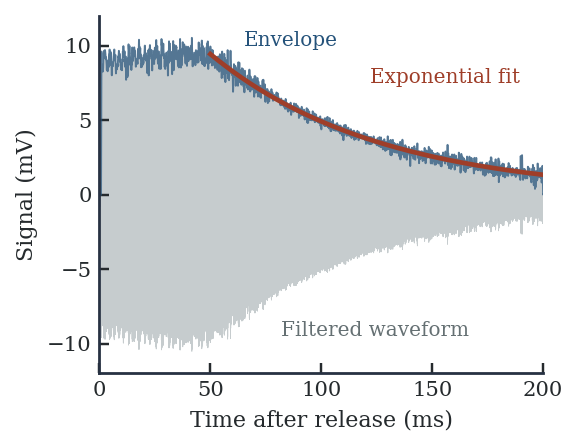

In [46]:
# Envolvente y ajuste del resultado ringdown_1625 original.
rd = ringdown_1625
with mpl.rc_context(PAPER_STYLE):
    fig_decay, ax_decay = plt.subplots(figsize=(89*MM,68*MM), layout='constrained')
    t = rd.time*1e3
    mask = rd.time>=rd.decay_start_time
    # Same filtered oscilloscope waveform used to calculate the envelope.
    ax_decay.plot(t,rd.filtered_signal*1e3,color='#BCC4C6',lw=.35,alpha=.85,rasterized=True,label='Filtered waveform',zorder=1)
    ax_decay.plot(t,rd.envelope*1e3,color=ACCENT,lw=.85,alpha=.7,rasterized=True,label='Envelope',zorder=2)
    ax_decay.plot(t[mask],rd.fit_curve[mask]*1e3,color=FIT,lw=2.1,label='Exponential fit',zorder=3)
    ax_decay.set(xlabel='Time after release (ms)',ylabel='Signal (mV)',xlim=(t[0],t[-1]),ylim=(-12,12))
    style_paper_axis(ax_decay)
    ax_decay.set_xticks([0,50,100,150,200]); ax_decay.set_yticks([-10,-5,0,5,10])
    ax_decay.text(65, 10, 'Envelope', color=ACCENT, fontsize=9)
    ax_decay.text(122, 7.5, 'Exponential fit', color=FIT, fontsize=9)
    ax_decay.text(82, -9.5, 'Filtered waveform', color='#657073', fontsize=9)
    collint_result = review_with_collint(fig_decay, 'figure_3_ringdown')
    fig_decay.savefig(PAPER_OUTPUT_DIR/'figure_3_ringdown.pdf')
    fig_decay.savefig(PAPER_OUTPUT_DIR/'figure_3_ringdown.png',dpi=400)


figure_4_spectrogram: collint actionable collisions=0; intentional overlaps ignored=1


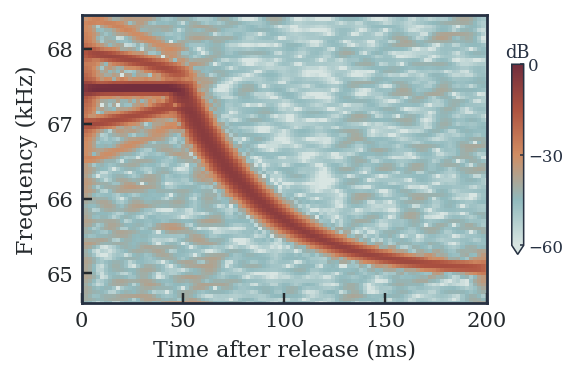

In [47]:
# Espectrograma del mismo ringdown, en una figura independiente.
rd = ringdown_1625
with mpl.rc_context(PAPER_STYLE):
    fig_spectrogram, ax_spec = plt.subplots(figsize=(89*MM,57*MM), layout='constrained')
    mesh = ax_spec.pcolormesh(rd.spectrogram_time*1e3, rd.spectrogram_frequency*1e-3, rd.spectrogram_decibels, cmap=POWER_CMAP, vmin=-60, vmax=0, shading='auto', rasterized=True)
    ax_spec.set(xlabel='Time after release (ms)', ylabel='Frequency (kHz)', ylim=np.asarray(rd.spectrogram_frequency_limits)*1e-3, xlim=(0,rd.time[-1]*1e3))
    style_paper_axis(ax_spec,image=True)
    ax_spec.set_xticks([0,50,100,150,200]); ax_spec.set_yticks([65,66,67,68])
    cb = fig_spectrogram.colorbar(mesh, ax=ax_spec, pad=.012, fraction=.03, aspect=16, shrink=.66, extend='min')
    cb.ax.set_title('dB', fontsize=8, pad=3)
    cb.set_ticks([-60,-30,0]); cb.ax.tick_params(labelsize=7.5,length=2,width=.7,pad=2)
    cb.outline.set_linewidth(.7)
    collint_result = review_with_collint(fig_spectrogram, 'figure_4_spectrogram')
    fig_spectrogram.savefig(PAPER_OUTPUT_DIR/'figure_4_spectrogram.pdf')
    fig_spectrogram.savefig(PAPER_OUTPUT_DIR/'figure_4_spectrogram.png',dpi=400)


In [48]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import signal
from Data import Ringdown

folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11")
files = [f for f in sorted(folder.glob("ringdown-02-11-*.csv"))
         if "reconstruida" not in f.stem and not f.stem.endswith("1637")]
if len(files) != 16:
    raise ValueError(f"Expected 16 recordings, found {len(files)}")

ringdown_grid_data = []

for file in files:
    rd = Ringdown(file)
    # The excitation channel drops to its noise floor when the generator switches off.
    samples_per_bin = max(1, round(0.001 / np.median(np.diff(rd.raw_time))))
    bins = rd.channel_2[:len(rd.channel_2) // samples_per_bin * samples_per_bin]
    rms = np.sqrt(np.mean(bins.reshape(-1, samples_per_bin) ** 2, axis=1))
    transition_bin = np.argmax(rms[:-3] - rms[3:])
    lo = transition_bin * samples_per_bin
    hi = min((transition_bin + 4) * samples_per_bin, len(rd.raw_time))
    fine_bins = max(1, round(0.0001 / np.median(np.diff(rd.raw_time))))
    region = rd.channel_2[lo:hi]
    region = region[:len(region) // fine_bins * fine_bins]
    fine_rms = np.sqrt(np.mean(region.reshape(-1, fine_bins) ** 2, axis=1))
    switch = lo + (np.argmax(fine_rms[:-1] - fine_rms[1:]) + 1) * fine_bins
    rd.reconstruct(rd.raw_time[switch], save=False)

    # Match Ringdown.analyze's STFT and Ringdown.plot's spectrogram.
    dt = np.median(np.diff(rd.time))
    nperseg = round(0.020 / dt)
    frequency, time, spectrum = signal.stft(
        rd.signal, fs=1 / dt, window="hann", nperseg=nperseg,
        noverlap=round(nperseg * 0.9), boundary="zeros", padded=True,
    )
    band = (frequency >= 63e3) & (frequency <= 72e3)
    frequency = frequency[band]
    power = np.abs(spectrum[band]) ** 2
    with np.errstate(divide="ignore"):
        decibels = 10 * np.log10(power / power.max())
    step = max(1, len(rd.raw_time) // 100_000)
    ringdown_grid_data.append({
        "raw_time": rd.raw_time[::step].copy() * 1e3,
        "time_limits": (rd.raw_time[0] * 1e3, rd.raw_time[-1] * 1e3),
        "channel_1": rd.channel_1[::step].copy() * 1e3,
        "channel_1_limits": (rd.channel_1.min() * 1e3, rd.channel_1.max() * 1e3),
        "channel_2": rd.channel_2[::step].copy(),
        "channel_2_limits": (rd.channel_2.min(), rd.channel_2.max()),
        "spectrogram_time": time * 1e3,
        "frequency": frequency * 1e-3,
        "decibels": decibels,
        "end_time": rd.time[-1] * 1e3,
    })


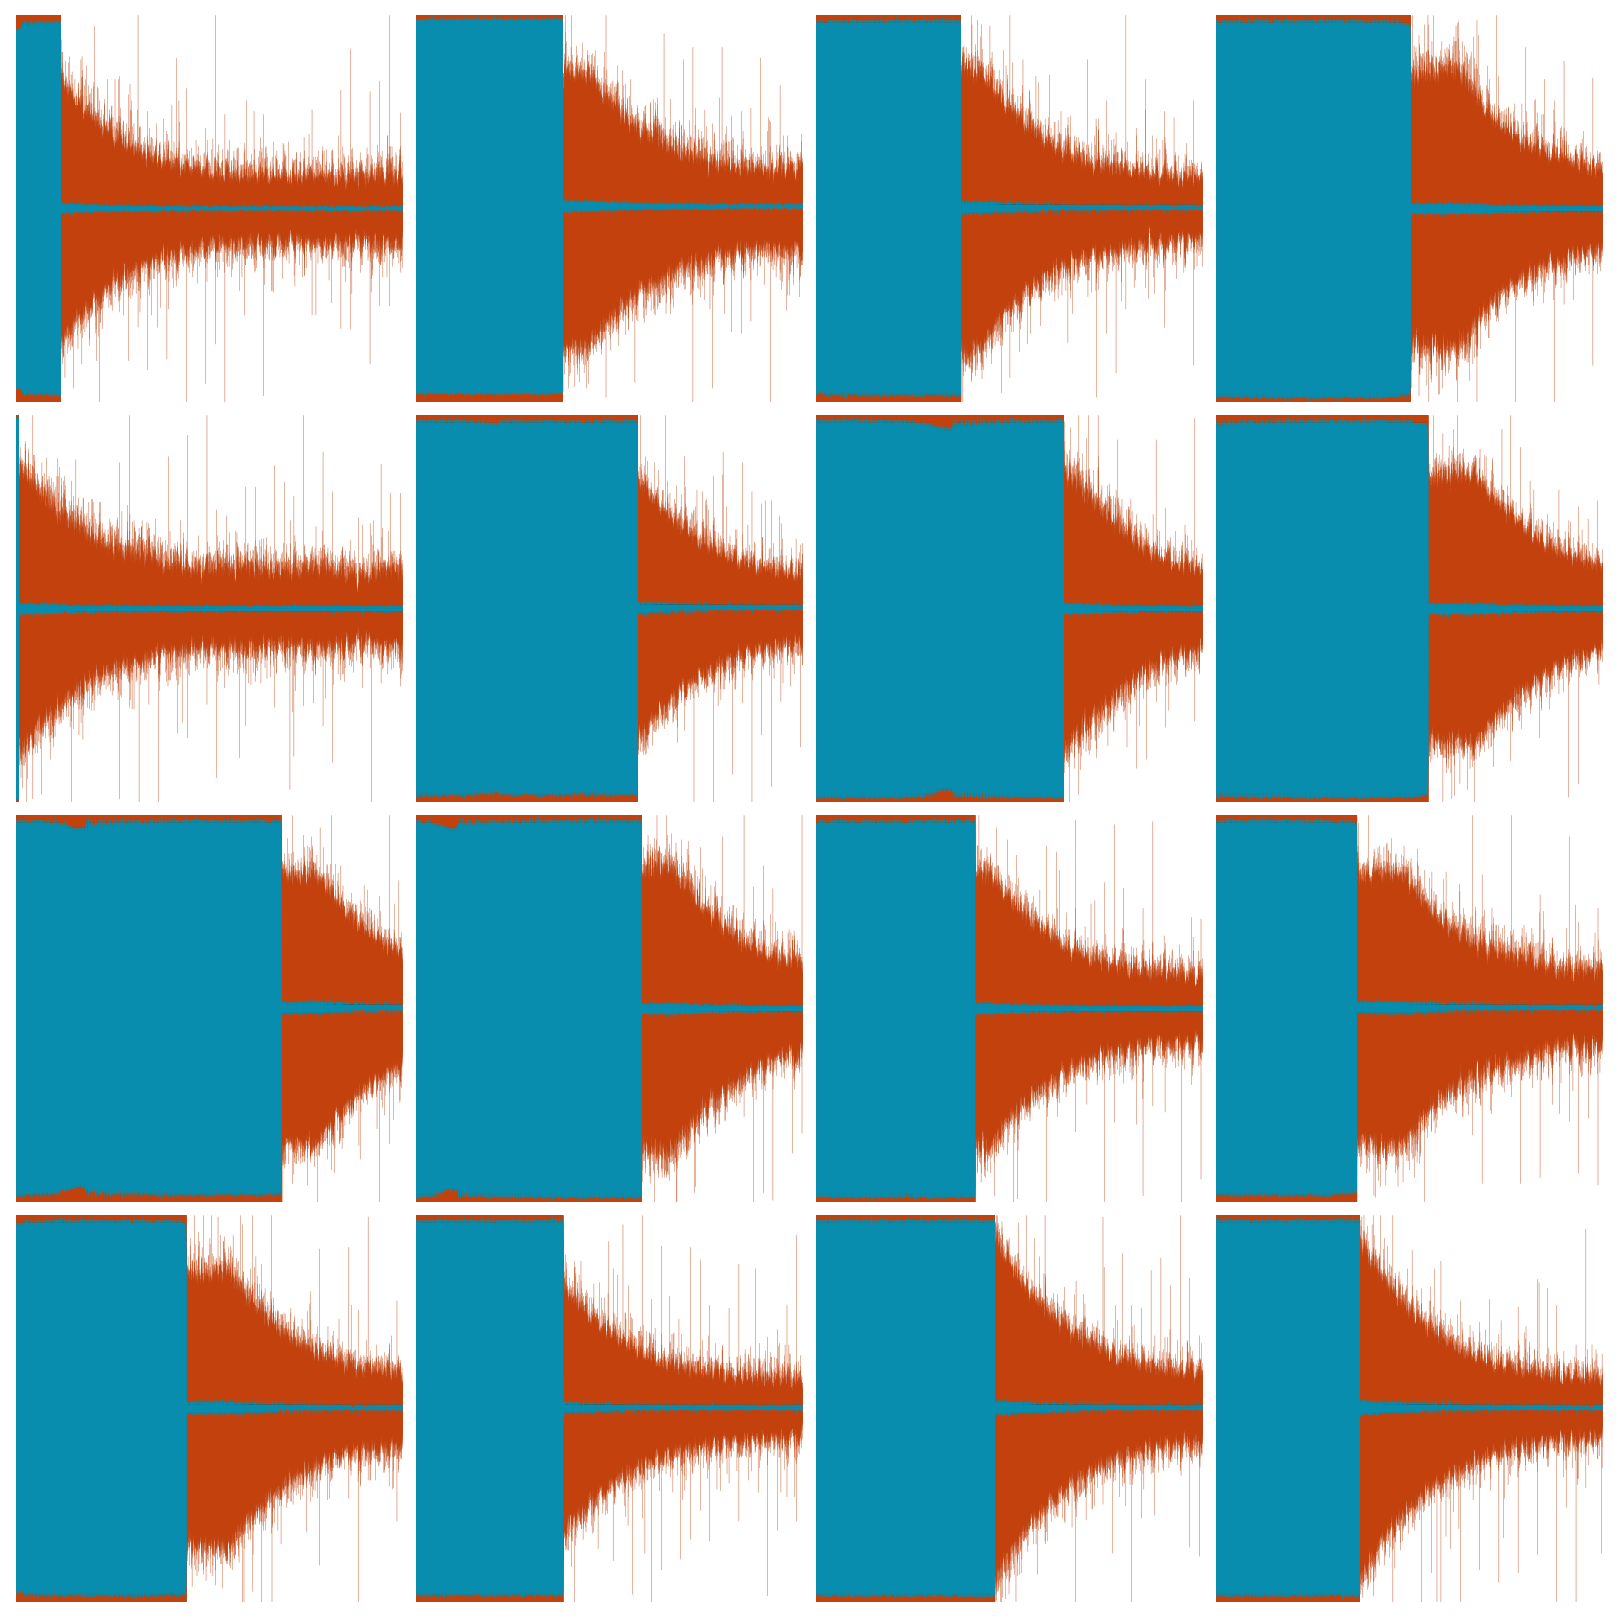

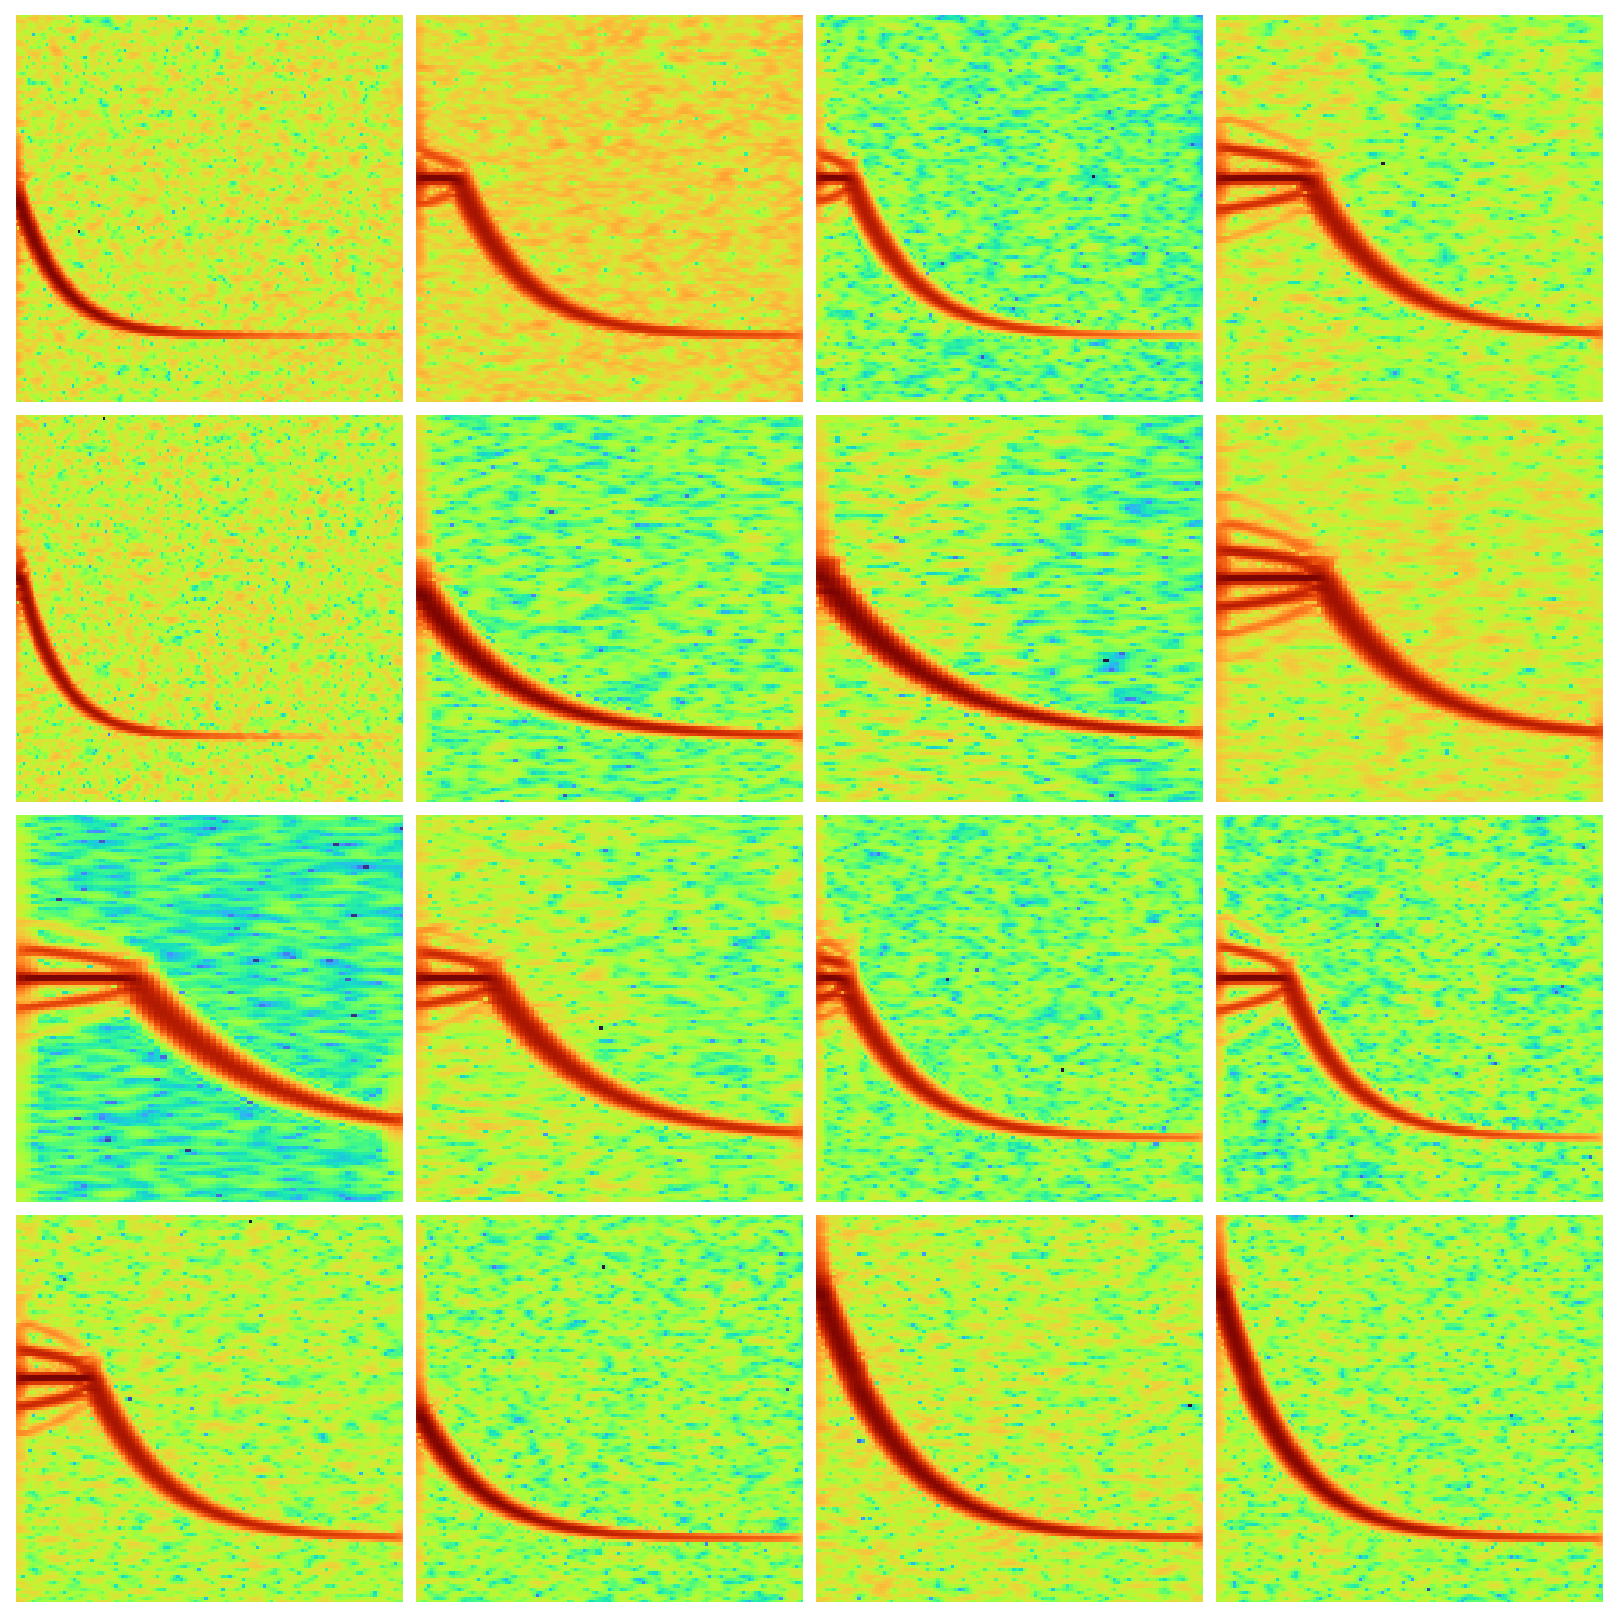

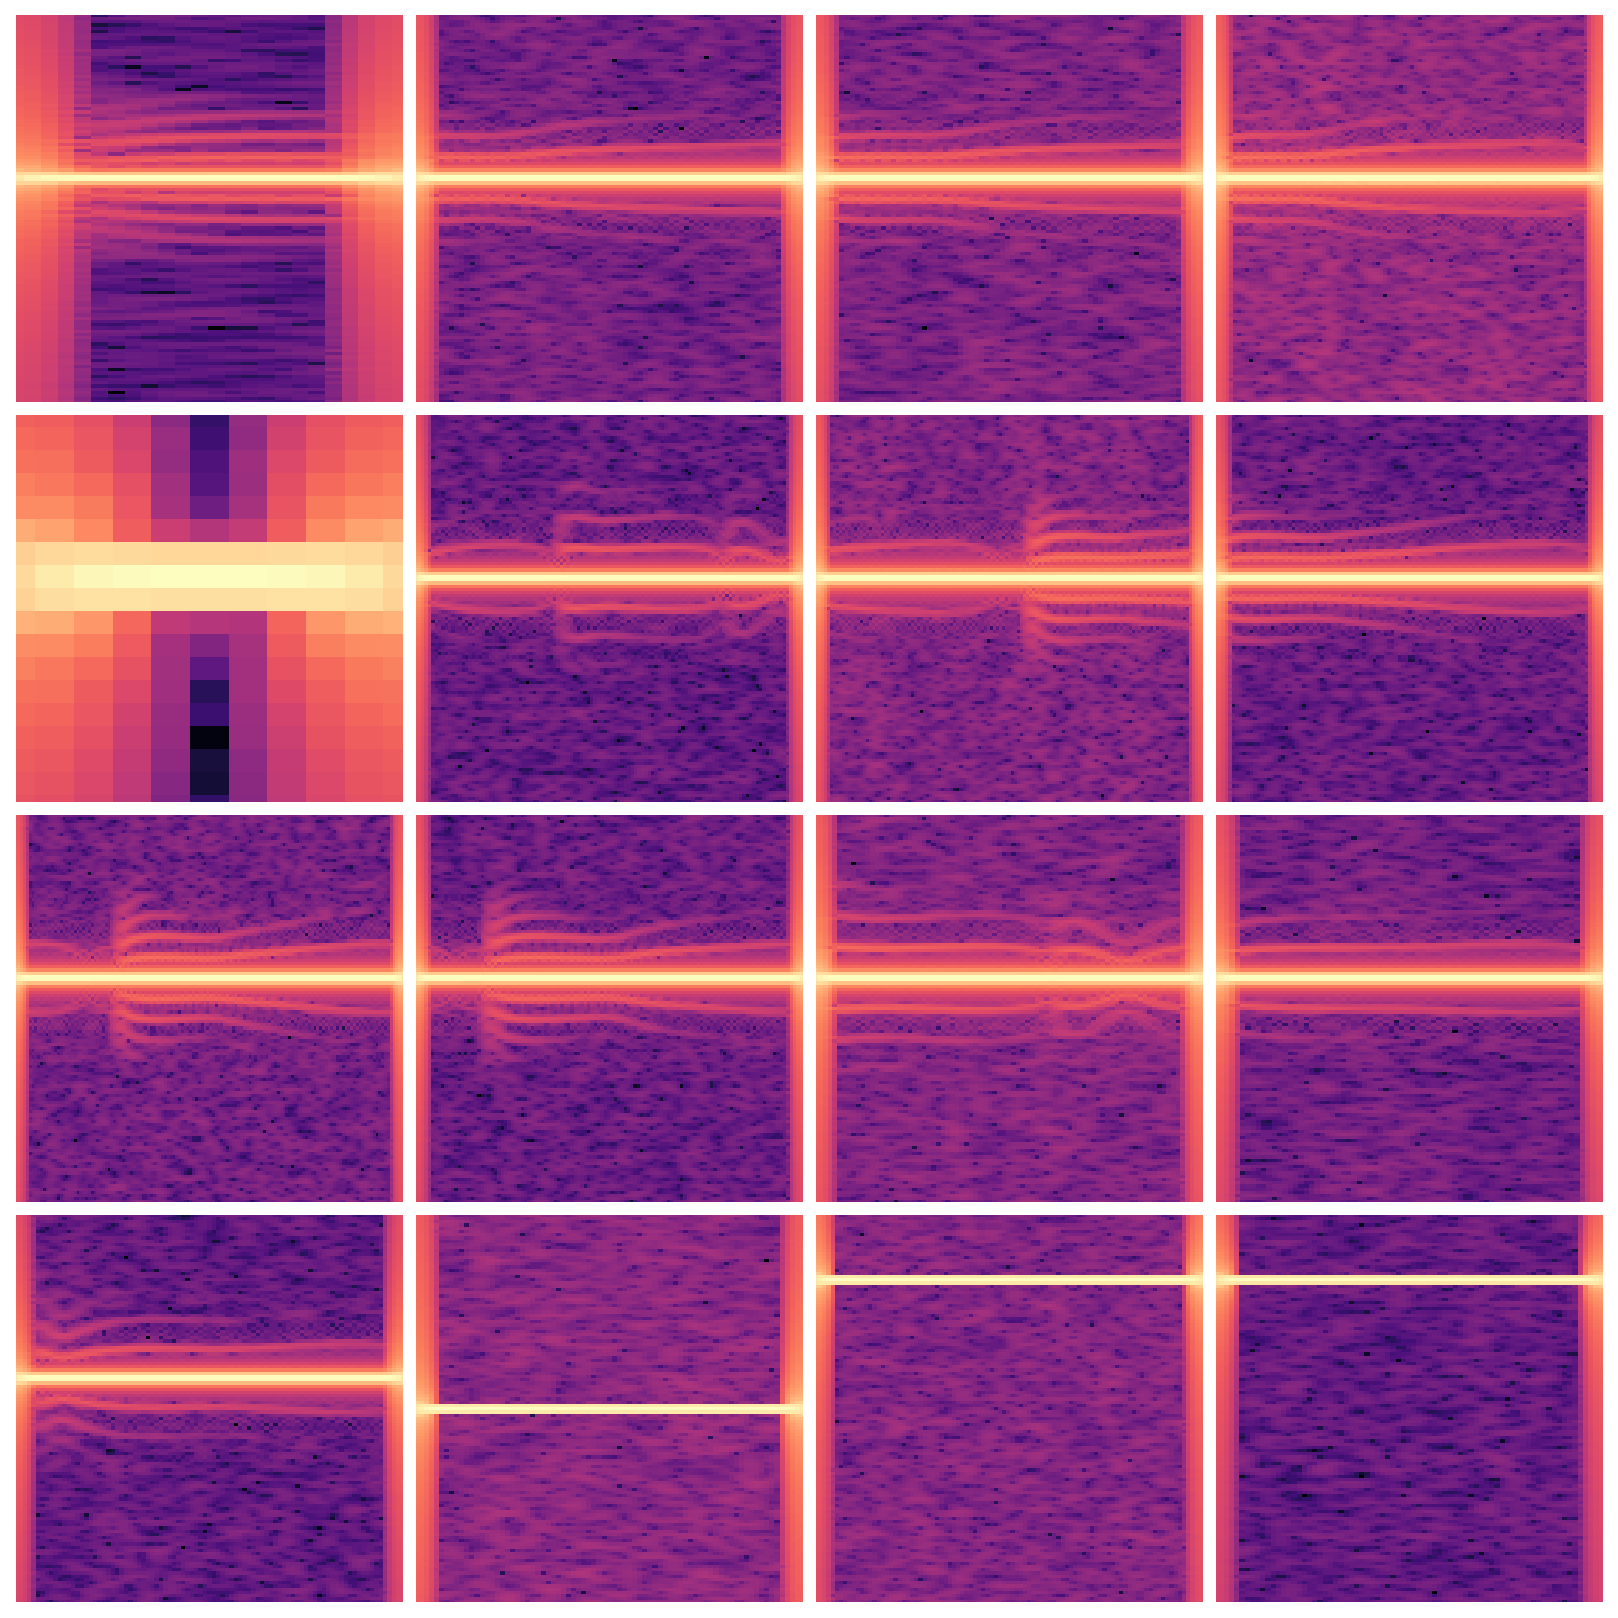

In [49]:
# Limites del eje de frecuencia del espectrograma, en kHz.
spectrogram_ylim = (64, 70)

fig_signals, signal_axes = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")
fig_spectrograms, spec_axes = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")

for data, ax, spec_ax in zip(ringdown_grid_data, signal_axes.flat, spec_axes.flat):
    for axis, values, limits, color in (
        (ax, data["channel_1"], data["channel_1_limits"], "#C2410C"),
        (ax.twinx(), data["channel_2"], data["channel_2_limits"], "#0891B2"),
    ):
        points = np.column_stack((data["raw_time"], values))
        axis.add_collection(LineCollection(np.stack((points[:-1], points[1:]), axis=1),
                                           colors=color, linewidths=0.18, alpha=0.55))
        axis.set_xlim(*data["time_limits"])
        axis.set_ylim(*limits)
        axis.set_axis_off()
    ax.set_box_aspect(1)

    spec_ax.pcolormesh(data["spectrogram_time"], data["frequency"], data["decibels"],
                       shading="auto", cmap="turbo", rasterized=True)
    spec_ax.set_xlim(0, data["end_time"])
    spec_ax.set_ylim(*spectrogram_ylim)
    spec_ax.set_box_aspect(1)
    spec_ax.set_axis_off()

plt.show()

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import signal
from Data import Ringdown

folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11")
files = [f for f in sorted(folder.glob("ringdown-02-11-*.csv"))
         if "reconstruida" not in f.stem and not f.stem.endswith("1637")]
if len(files) != 16:
    raise ValueError(f"Expected 16 recordings, found {len(files)}")

# Espectrogramas de CH2 antes del corte, en el mismo orden que la grilla posterior.
fig_before, axes_before = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")
for file, ax in zip(files, axes_before.flat):
    rd = Ringdown(file)
    # The excitation channel drops to its noise floor when the generator switches off.
    samples_per_bin = max(1, round(0.001 / np.median(np.diff(rd.raw_time))))
    bins = rd.channel_2[:len(rd.channel_2) // samples_per_bin * samples_per_bin]
    rms = np.sqrt(np.mean(bins.reshape(-1, samples_per_bin) ** 2, axis=1))
    transition_bin = np.argmax(rms[:-3] - rms[3:])
    lo = transition_bin * samples_per_bin
    hi = min((transition_bin + 4) * samples_per_bin, len(rd.raw_time))
    fine_bins = max(1, round(0.0001 / np.median(np.diff(rd.raw_time))))
    region = rd.channel_2[lo:hi]
    region = region[:len(region) // fine_bins * fine_bins]
    fine_rms = np.sqrt(np.mean(region.reshape(-1, fine_bins) ** 2, axis=1))
    switch = lo + (np.argmax(fine_rms[:-1] - fine_rms[1:]) + 1) * fine_bins
    rd.reconstruct(rd.raw_time[switch], save=False)

    before = rd.raw_time < rd.release_time
    dt = np.median(np.diff(rd.raw_time))
    values = rd.channel_2[before]
    nperseg = min(round(0.020 / dt), len(values))
    frequency, time, spectrum = signal.stft(
        values, fs=1 / dt, window="hann", nperseg=nperseg,
        noverlap=round(nperseg * 0.9), boundary="zeros", padded=True,
    )
    band = (frequency >= 63e3) & (frequency <= 72e3)
    power = np.abs(spectrum[band]) ** 2
    with np.errstate(divide="ignore"):
        decibels = 10 * np.log10(power / power.max())
    time = (rd.raw_time[before][0] - rd.release_time + time) * 1e3
    ax.pcolormesh(time, frequency[band] * 1e-3, decibels,
                  shading="auto", cmap="magma", rasterized=True)
    ax.set_xlim((rd.raw_time[0] - rd.release_time) * 1e3, 0)
    ax.set_ylim(64, 70)
    ax.set_box_aspect(1)
    ax.set_axis_off()
plt.show()


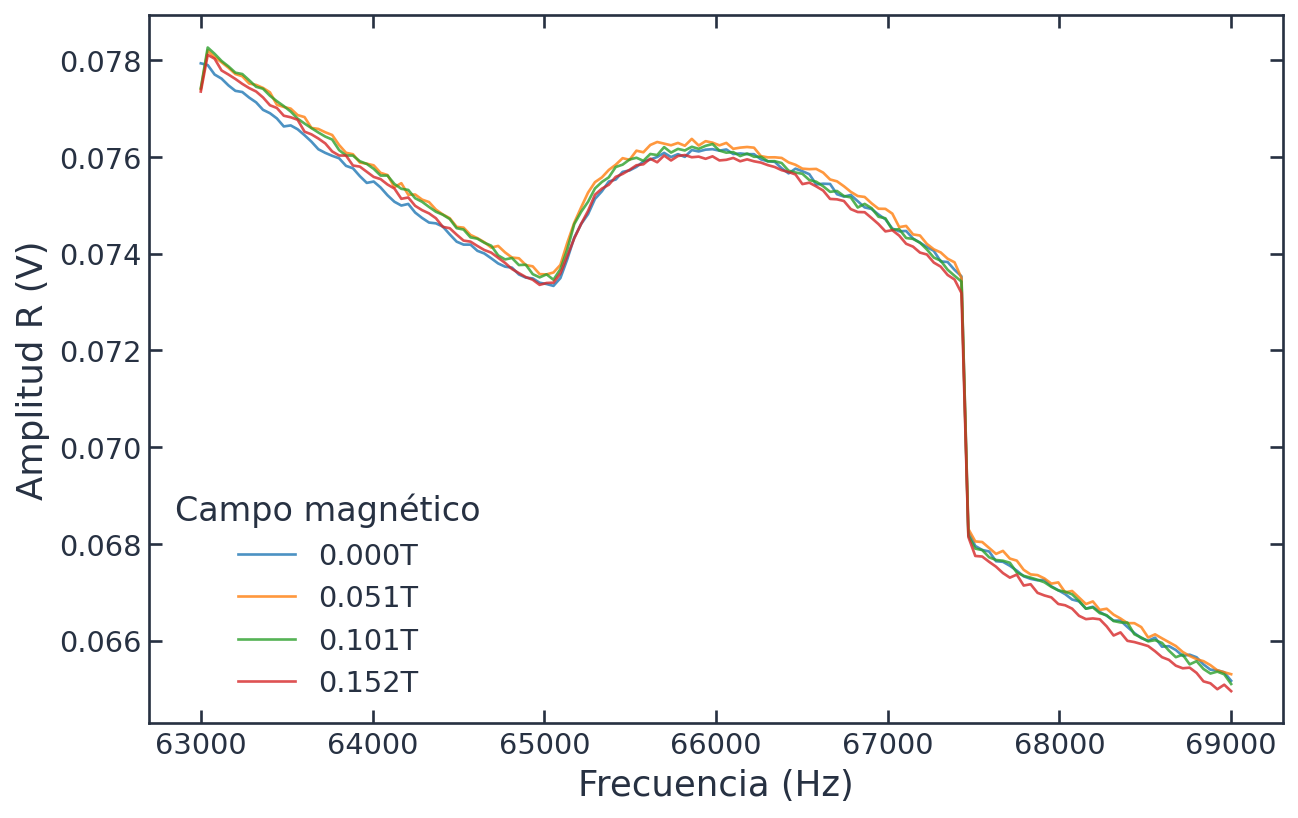

In [50]:
from pathlib import Path
import matplotlib.pyplot as plt
from Data import Sweep

folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Campo_mag_19-11")
files = sorted(folder.glob("field_*.csv"))
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
# Sweep.plot dibuja X, Y y R; conservamos solo el eje de R.
ax_x = fig.add_axes([0, 0, 0.01, 0.01])
ax_y = fig.add_axes([0, 0, 0.01, 0.01])
for file in files:
    field = file.stem.removeprefix("field_")
    Sweep(file).plot(axes=(ax_x, ax_y, ax), label=field)
fig.delaxes(ax_x)
fig.delaxes(ax_y)
ax.set(xlabel="Frecuencia (Hz)", ylabel="Amplitud R (V)")
ax.legend(title="Campo magnético")
plt.show()


Incluidos (16): 1620, 1621, 1623, 1625, 1634, 1635, 1637, 1638, 1643, 1647, 1650, 1651, 1652, 1655, 1657, 1658
Excluidos, sin tramo excitado suficiente: 1631


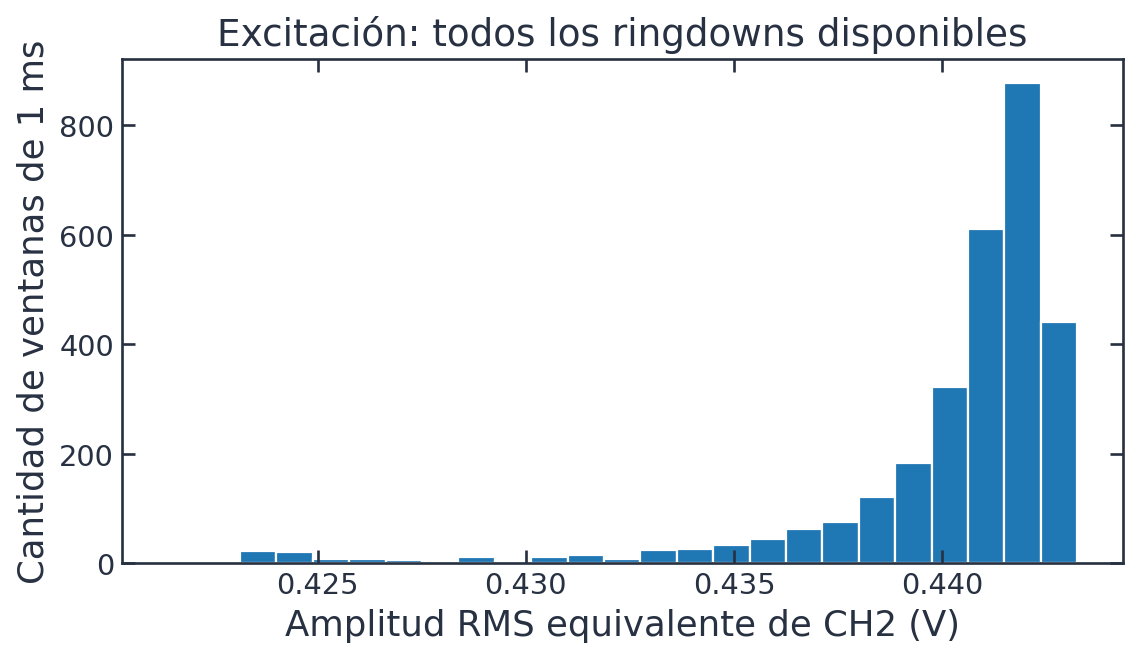

In [51]:
# Histograma de amplitudes de CH2 durante la excitación (incluye crosstalk).
# Cada amplitud es sqrt(2) * RMS en una ventana de 1 ms.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from Data import Ringdown

folder = Path(r"C:\Main\Repos\MEMS\Mediciones\Ringdowns del 2-11")
amplitudes_iniciales = {}
amplitudes_excitadas = []
incluidos, excluidos = [], []
for file in sorted(folder.glob("ringdown-02-11-*.csv")):
    if "reconstruida" in file.stem:
        continue
    nombre = file.stem[-4:]
    rd = Ringdown(file)
    dt = np.median(np.diff(rd.raw_time))
    n = round(0.001 / dt)
    # Detectar el apagado por la caída de RMS de CH2, como en la grilla anterior.
    bloques = rd.channel_2[:len(rd.channel_2) // n * n].reshape(-1, n)
    rms = np.sqrt(np.mean(bloques**2, axis=1))
    i = np.argmax(rms[:-3] - rms[3:])
    # Exigir al menos 10 ms de señal excitada antes de la transición.
    if i < 10:
        excluidos.append(nombre)
        continue
    lo, hi = i * n, min((i + 4) * n, len(rd.raw_time))
    nf = max(1, round(0.0001 / dt))
    region = rd.channel_2[lo:hi]
    region = region[:len(region) // nf * nf].reshape(-1, nf)
    rms_fino = np.sqrt(np.mean(region**2, axis=1))
    switch = lo + (np.argmax(rms_fino[:-1] - rms_fino[1:]) + 1) * nf
    antes = rd.channel_2[:switch]
    bloques = antes[len(antes) % n:].reshape(-1, n)
    amplitudes_excitadas.extend(np.sqrt(2 * np.mean(bloques**2, axis=1)))
    incluidos.append(nombre)
    # Misma ventana de 1 ms previa al corte detectado para cada registro.
    amplitudes_iniciales[nombre] = np.sqrt(2 * np.mean(antes[-n:]**2))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(amplitudes_excitadas, bins=25, color="tab:blue", edgecolor="white")
ax.set(xlabel="Amplitud RMS equivalente de CH2 (V)", ylabel="Cantidad de ventanas de 1 ms", title="Excitación: todos los ringdowns disponibles")
print(f"Incluidos ({len(incluidos)}): {', '.join(incluidos)}")
print(f"Excluidos, sin tramo excitado suficiente: {', '.join(excluidos) or 'ninguno'}")
plt.show()


1620: amplitud = 0.4402 V, inicio del decaimiento aprox. 0 ms
1621: amplitud = 0.4341 V, inicio del decaimiento aprox. 26 ms
1623: amplitud = 0.4406 V, inicio del decaimiento aprox. 20 ms
1625: amplitud = 0.4214 V, inicio del decaimiento aprox. 50 ms
1634: amplitud = 0.4414 V, inicio del decaimiento aprox. 0 ms
1635: amplitud = 0.4412 V, inicio del decaimiento aprox. 0 ms
1637: amplitud = 0.4262 V, inicio del decaimiento aprox. 0 ms
1638: amplitud = 0.4289 V, inicio del decaimiento aprox. 48 ms
1643: amplitud = 0.4336 V, inicio del decaimiento aprox. 37 ms
1647: amplitud = 0.4409 V, inicio del decaimiento aprox. 34 ms
1650: amplitud = 0.4314 V, inicio del decaimiento aprox. 18 ms
1651: amplitud = 0.4374 V, inicio del decaimiento aprox. 49 ms
1652: amplitud = 0.4344 V, inicio del decaimiento aprox. 43 ms
1655: amplitud = 0.4335 V, inicio del decaimiento aprox. 0 ms
1657: amplitud = 0.4302 V, inicio del decaimiento aprox. 0 ms
1658: amplitud = 0.4287 V, inicio del decaimiento aprox. 0 ms

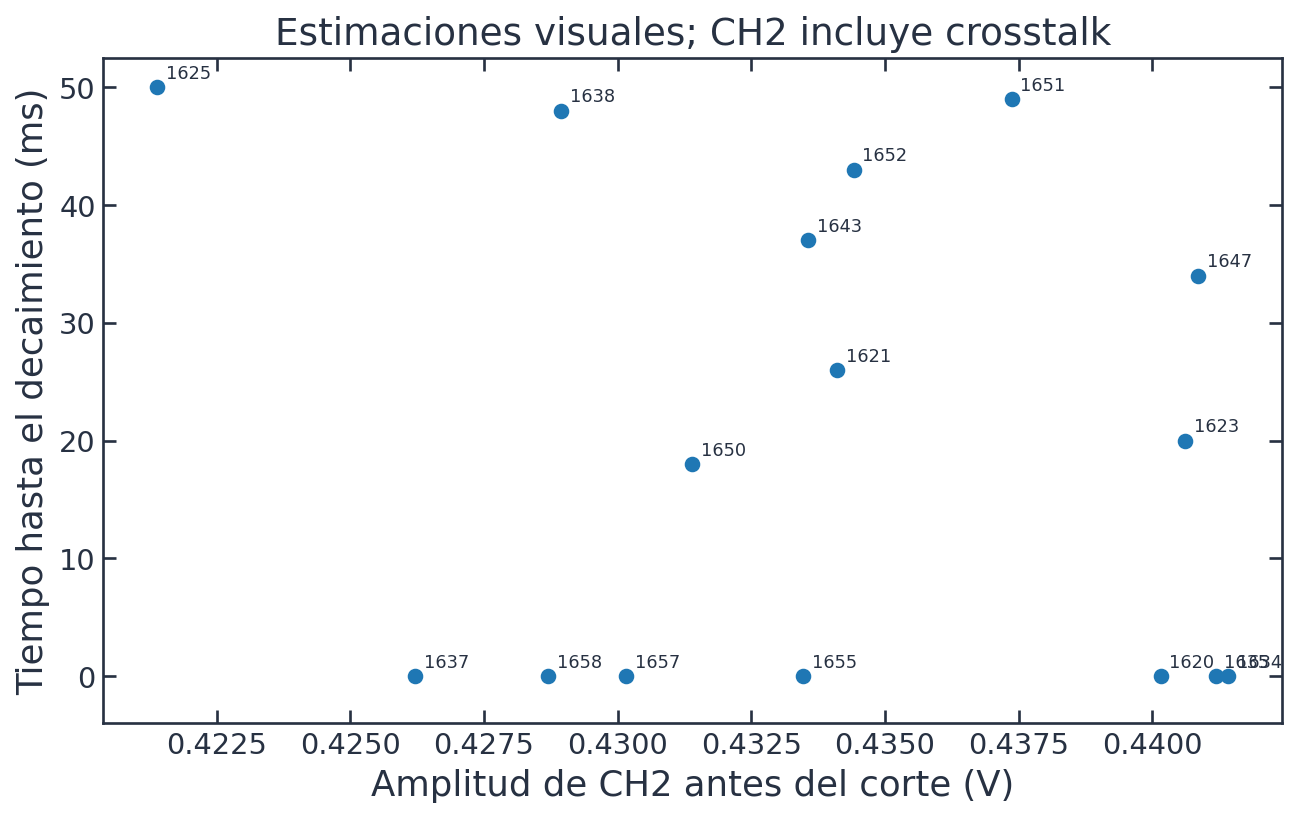

In [52]:
# Inicio del decaimiento estimado visualmente en CH1, en ms desde el apagado.
# Se inspeccionó sqrt(2)*RMS en ventanas de 1 ms; 0 indica decaimiento inmediato.
# Son estimaciones visuales aproximadas, no resultados de un ajuste automático.
coherencia_ms = {
    "1620": 0, "1621": 26, "1623": 20, "1625": 50,
    "1634": 0, "1635": 0, "1637": 0, "1638": 48,
    "1643": 37, "1647": 34, "1650": 18, "1651": 49,
    "1652": 43, "1655": 0, "1657": 0, "1658": 0,
}
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for nombre, tiempo in coherencia_ms.items():
    if nombre not in amplitudes_iniciales:
        print(f"{nombre}: sin amplitud inicial disponible")
        continue
    amplitud = amplitudes_iniciales[nombre]
    ax.scatter(amplitud, tiempo, color="tab:blue")
    ax.annotate(nombre, (amplitud, tiempo), xytext=(4, 4), textcoords="offset points", fontsize=8)
    print(f"{nombre}: amplitud = {amplitud:.4f} V, inicio del decaimiento aprox. {tiempo} ms")
ax.set(xlabel="Amplitud de CH2 antes del corte (V)", ylabel="Tiempo hasta el decaimiento (ms)", title="Estimaciones visuales; CH2 incluye crosstalk")
ax.set_ylim(bottom=-4)
plt.show()


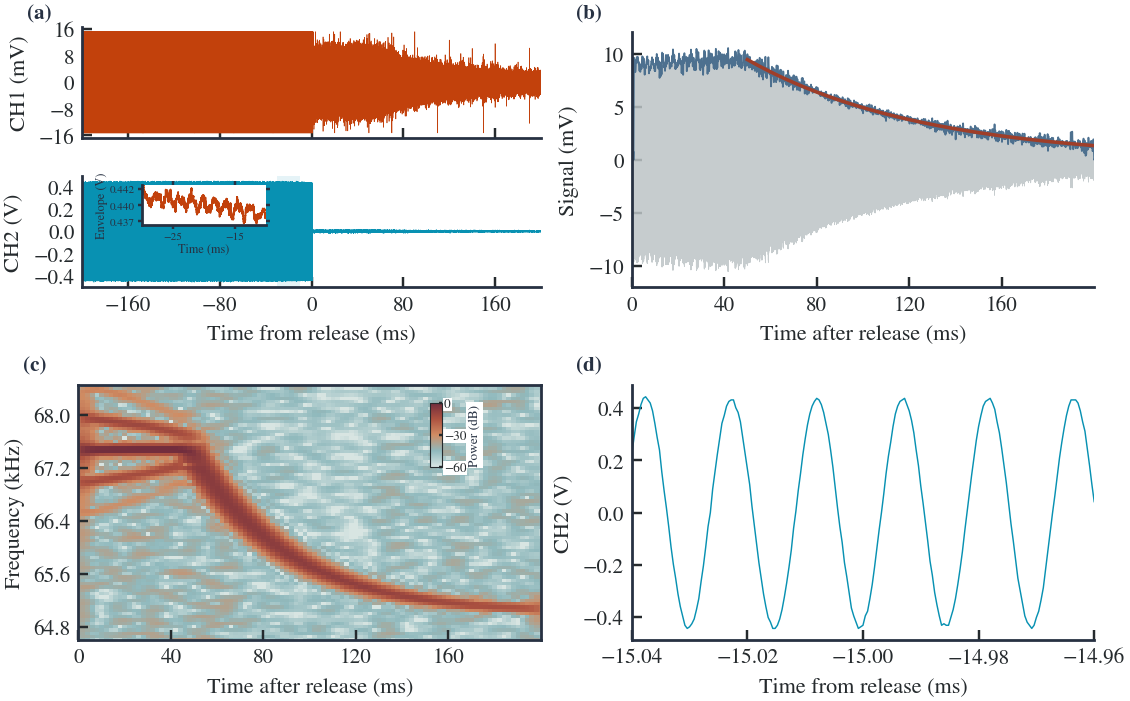

In [53]:
# Cuadricula de cuatro paneles; todas las curvas proceden de ringdown-02-11-1625.csv.
from scipy.signal import hilbert
from scipy.ndimage import uniform_filter1d

rd = ringdown_1625
raw_t_ms = (rd.raw_time - rd.release_time) * 1e3
step = max(1, len(raw_t_ms) // 100_000)
ch1_mv = rd.channel_1 * 1e3
ch2_v = rd.channel_2
pre_cut = raw_t_ms < 0
pre_t = raw_t_ms[pre_cut]
ch2_pre = ch2_v[pre_cut]
ch2_envelope = np.abs(hilbert(ch2_pre))
# Moving average of 0.15 ms (~10 carrier cycles), used only to display the measured envelope.
samples_per_smoothing = max(1, round(0.00015 / np.median(np.diff(rd.raw_time))))
ch2_envelope_smooth = uniform_filter1d(ch2_envelope, size=samples_per_smoothing, mode='nearest')
env_window = (pre_t >= -30) & (pre_t <= -10)
# Short raw-waveform view: about five cycles, plotted with every original sample.
wave_window = (pre_t >= -15.040) & (pre_t <= -14.960)

with mpl.rc_context(PAPER_STYLE):
    fig_ringdown_grid, axes = plt.subplots(2, 2, figsize=(180*MM, 112*MM), layout='constrained')
    ax_raw, ax_decay, ax_spec, ax_wave = axes.flat

    # (a) Separate aligned axes preserve both measured channels without color mixing.
    raw_spec = ax_raw.get_subplotspec()
    ax_raw.remove()
    raw_grid = raw_spec.subgridspec(2, 1, hspace=.08)
    ax_raw = fig_ringdown_grid.add_subplot(raw_grid[0])
    ax_raw_r = fig_ringdown_grid.add_subplot(raw_grid[1], sharex=ax_raw)
    ax_raw.plot(raw_t_ms[::step], ch1_mv[::step], color='#C2410C', lw=.3, rasterized=True)
    ax_raw.set(ylabel='CH1 (mV)', xlim=(raw_t_ms[0], raw_t_ms[-1]))
    style_paper_axis(ax_raw)
    ax_raw.tick_params(labelbottom=False)
    ax_raw_r.plot(raw_t_ms[::step], ch2_v[::step], color='#0891B2', lw=.3, rasterized=True)
    ax_raw_r.set(xlabel='Time from release (ms)', ylabel='CH2 (V)')
    style_paper_axis(ax_raw_r)
    ax_raw_r.axvspan(-30, -10, color='#0891B2', alpha=.1, lw=0)
    ax_raw.text(-.12, 1.04, '(a)', transform=ax_raw.transAxes, ha='left', va='bottom', fontweight='bold', clip_on=False)
    env_ax = ax_raw_r.inset_axes([.13,.56,.27,.36])
    env_ax.set_facecolor('white'); env_ax.set_zorder(10)
    env_ax.plot(pre_t[env_window], ch2_envelope_smooth[env_window], color='#C2410C', lw=.8)
    env_values = ch2_envelope_smooth[env_window]
    env_lo, env_hi = np.quantile(env_values,[.01,.99])
    env_pad = max((env_hi-env_lo)*.12, 1e-5)
    env_ax.set(xlim=(-30,-10), ylim=(env_lo-env_pad,env_hi+env_pad))
    env_ax.set_xticks([-25,-15]); env_ax.set_yticks(np.linspace(env_lo,env_hi,3))
    env_ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.3f'))
    env_ax.tick_params(labelsize=5, length=2, pad=1, direction='out')
    env_ax.set_ylabel('Envelope (V)', fontsize=5.5, labelpad=1)
    env_ax.set_xlabel('Time (ms)', fontsize=5.5, labelpad=1)
    env_ax.spines[['top','right']].set_visible(False)

    # (b) Existing filtered waveform, envelope and exponential fit.
    t_ms = rd.time * 1e3
    fit_mask = rd.time >= rd.decay_start_time
    ax_decay.plot(t_ms, rd.filtered_signal*1e3, color='#BCC4C6', lw=.35, alpha=.85, rasterized=True)
    ax_decay.plot(t_ms, rd.envelope*1e3, color=ACCENT, lw=.8, alpha=.75, rasterized=True)
    ax_decay.plot(t_ms[fit_mask], rd.fit_curve[fit_mask]*1e3, color=FIT, lw=1.6)
    ax_decay.set(xlabel='Time after release (ms)', ylabel='Signal (mV)', xlim=(t_ms[0], t_ms[-1]), ylim=(-12, 12))
    style_paper_axis(ax_decay)
    ax_decay.text(-.12, 1.04, '(b)', transform=ax_decay.transAxes, ha='left', va='bottom', fontweight='bold', clip_on=False)

    # (c) Existing spectrogram; compact colorbar inside the axes.
    mesh = ax_spec.pcolormesh(rd.spectrogram_time*1e3, rd.spectrogram_frequency*1e-3,
        rd.spectrogram_decibels, cmap=POWER_CMAP, vmin=-60, vmax=0, shading='auto', rasterized=True)
    ax_spec.set(xlabel='Time after release (ms)', ylabel='Frequency (kHz)',
        ylim=np.asarray(rd.spectrogram_frequency_limits)*1e-3, xlim=(0, t_ms[-1]))
    style_paper_axis(ax_spec, image=True)
    ax_spec.text(-.12, 1.04, '(c)', transform=ax_spec.transAxes, ha='left', va='bottom', fontweight='bold', clip_on=False)
    cb_ax = ax_spec.inset_axes([.76,.68,.025,.25])
    cb_ax.set_facecolor('white'); cb_ax.patch.set_alpha(1.0); cb_ax.set_zorder(10)
    cb = fig_ringdown_grid.colorbar(mesh, cax=cb_ax, ticks=[-60,-30,0])
    cb.ax.tick_params(labelsize=6,length=1.5,pad=1,colors=INK); cb.ax.set_ylabel('Power (dB)', fontsize=6, labelpad=1); cb.ax.yaxis.label.set_bbox({'facecolor':'white','edgecolor':'none','pad':1}); [label.set_bbox({'facecolor':'white','edgecolor':'none','pad':.5}) for label in cb.ax.get_yticklabels()]
    cb.outline.set_edgecolor(INK); cb.outline.set_linewidth(.5)

    # (d) A few real CH2 oscillation periods with the measured smoothed +/- envelope.
    ax_wave.plot(pre_t[wave_window], ch2_pre[wave_window], color='#0891B2', lw=.65, zorder=2)
    ax_wave.set(xlabel='Time from release (ms)', ylabel='CH2 (V)', xlim=(-15.040,-14.960))
    style_paper_axis(ax_wave)
    ax_wave.text(-.12, 1.04, '(d)', transform=ax_wave.transAxes, ha='left', va='bottom', fontweight='bold', clip_on=False)

    grid_path = PAPER_OUTPUT_DIR/'ringdown_1625_four_panel_grid'
    fig_ringdown_grid.savefig(grid_path.with_suffix('.pdf'))
    fig_ringdown_grid.savefig(grid_path.with_suffix('.png'), dpi=400)
    plt.show()


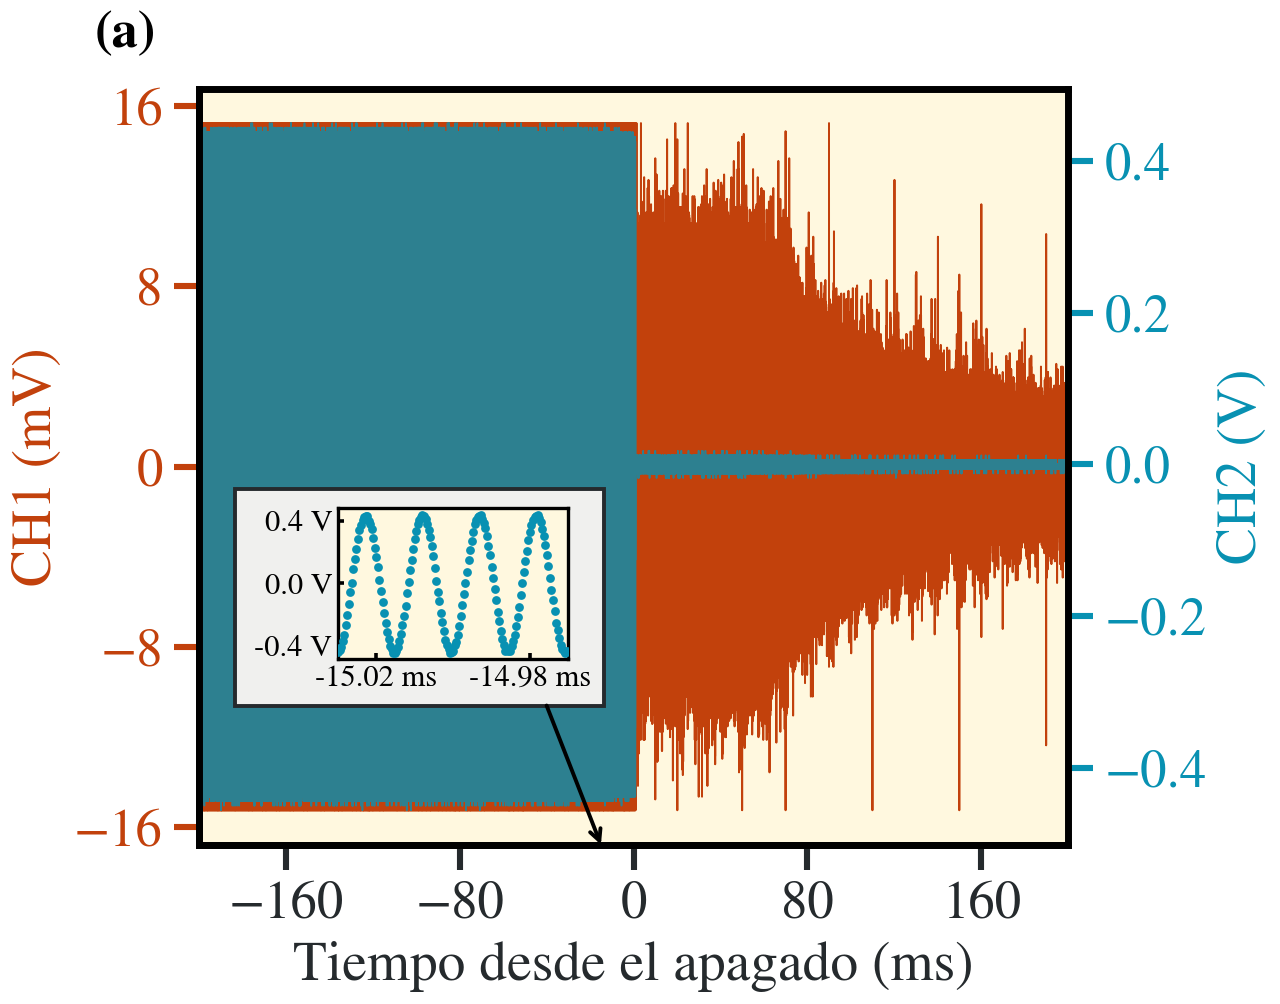

In [54]:
# Panel independiente: muestras medidas e inset de ciclos reales de CH2.
rd = ringdown_1625
raw_t_ms = (rd.raw_time - rd.release_time) * 1e3
ch1_mv = rd.channel_1 * 1e3
ch2_v = rd.channel_2
step = max(1, len(raw_t_ms) // 100_000)
wave_window = (raw_t_ms >= -15.030) & (raw_t_ms <= -14.970)
with mpl.rc_context(PAPER_STYLE):
    fig_raw, ax_ch1 = plt.subplots(figsize=(92*MM, 92*MM))
    fig_raw.subplots_adjust(left=.20, right=.80, bottom=.17, top=.95)
    fig_raw.set_facecolor('none')
    ax_ch1.set_facecolor('#FFF8DF')
    ax_ch1.set_box_aspect(1/1.15)
    ax_ch1.plot(raw_t_ms[::step], ch1_mv[::step], color='#C2410C', lw=.35, rasterized=True)
    ax_ch1.set(xlabel='Tiempo desde el apagado (ms)', ylabel='CH1 (mV)', xlim=(raw_t_ms[0], raw_t_ms[-1]))
    style_paper_axis(ax_ch1)
    ax_ch1.text(-.12, 1.04, '(a)', transform=ax_ch1.transAxes, ha='left', va='bottom', fontsize=9.5, fontweight='bold', clip_on=False, bbox={'facecolor':'white','edgecolor':'none','pad':1})
    ax_ch1.set_ylabel('CH1 (mV)', color='#C2410C', labelpad=2)
    ax_ch1.xaxis.labelpad = 2
    ax_ch1.tick_params(axis='y', colors='#C2410C', pad=2, direction='out')
    ax_ch1.tick_params(axis='x', pad=2, direction='out')
    ax_ch2 = ax_ch1.twinx()
    ax_ch2.patch.set_visible(False)
    ax_ch2.set_box_aspect(1/1.15)
    ax_ch2.plot(raw_t_ms[::step], ch2_v[::step], color='#0891B2', lw=.3, alpha=.8, rasterized=True)
    ax_ch2.set_ylabel('CH2 (V)', color='#0891B2', labelpad=2)
    ax_ch2.tick_params(axis='y', colors='#0891B2', pad=2, direction='out')
    # La flecha identifica el centro temporal del inset en el eje principal.
    marker_x = (-15 - raw_t_ms[0]) / (raw_t_ms[-1] - raw_t_ms[0])
    ax_ch2.annotate('', xy=(marker_x, 0), xytext=(.40, .184),
                    xycoords=ax_ch2.transAxes, textcoords=ax_ch2.transAxes,
                    arrowprops=dict(arrowstyle='->', color='black', lw=.7,
                                    mutation_scale=5, shrinkA=0, shrinkB=0), zorder=20)
    ax_ch2.add_patch(mpl.patches.Rectangle((.041, .184), .425, .286, transform=ax_ch2.transAxes,
                                           facecolor='#F0F0EE', edgecolor='#252A2D', linewidth=.7, zorder=9))
    ax_zoom = ax_ch2.inset_axes([.16, .245, .265, .20])
    ax_zoom.set_facecolor('#FFF8DF')
    ax_zoom.set_zorder(10)
    ax_zoom.scatter(raw_t_ms[wave_window], ch2_v[wave_window], s=2.5, color='#0891B2', linewidths=0, zorder=3)
    ax_zoom.set_xlim(-15.030, -14.970)
    ax_zoom.xaxis.set_major_locator(mpl.ticker.FixedLocator([-15.02, -14.98]))
    ax_zoom.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
    ax_zoom.tick_params(labelsize=5.5, length=1, width=.65, pad=1, direction='in')
    ax_zoom.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, pos: f'{x:.2f} ms'))
    ax_zoom.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda y, pos: f'{y:.1f} V'))
    ax_zoom.set_xlabel('')
    ax_zoom.set_ylabel('')
    for spine in ax_zoom.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(.6)
    raw_path = PAPER_OUTPUT_DIR/'ringdown_1625_raw_channels_inset'
    fig_raw.savefig(raw_path.with_suffix('.pdf'), facecolor=fig_raw.get_facecolor())
    fig_raw.savefig(raw_path.with_suffix('.png'), dpi=400, facecolor=fig_raw.get_facecolor())
    plt.show()


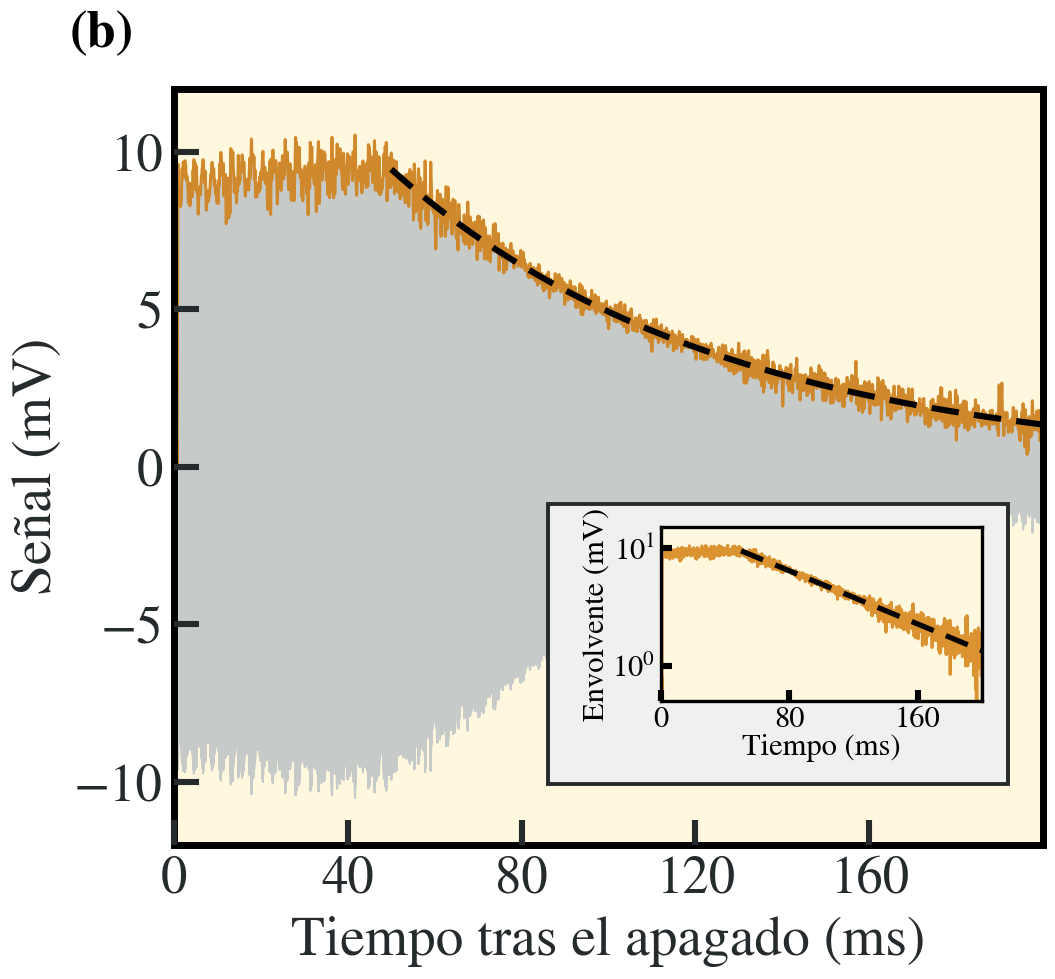

In [55]:
# Panel independiente con la misma envolvente y el mismo ajuste del panel (b).
# Appearance controls shared by the main plot and semilog inset.
ENVELOPE_COLOR = '#D27600'
ENVELOPE_LINEWIDTH_PT = .55
ENVELOPE_ALPHA = .78
FIT_COLOR = '#000000'
FIT_MAIN_LINEWIDTH_PT = 1.1
FIT_INSET_LINEWIDTH_PT = .95
FIT_DASH_PATTERN_PT = (4.5, 2.5)
FIT_LINESTYLE = (0, FIT_DASH_PATTERN_PT)

rd = ringdown_1625
t_ms = rd.time * 1e3
fit_mask = rd.time >= rd.decay_start_time
with mpl.rc_context(PAPER_STYLE):
    fig_decay_inset, ax_decay_inset = plt.subplots(figsize=(92*MM, 92*MM))
    fig_decay_inset.subplots_adjust(left=.20, right=.80, bottom=.17, top=.95)
    fig_decay_inset.set_facecolor('none')
    ax_decay_inset.set_facecolor('#FFF8DF')
    ax_decay_inset.set_box_aspect(1/1.15)
    ax_decay_inset.plot(t_ms, rd.filtered_signal*1e3, color='#BCC4C6', lw=.35, alpha=.85, rasterized=True, label='Filtered waveform')
    ax_decay_inset.plot(t_ms, rd.envelope*1e3, color=ENVELOPE_COLOR, lw=ENVELOPE_LINEWIDTH_PT, alpha=ENVELOPE_ALPHA, rasterized=True, label='Envelope')
    ax_decay_inset.plot(t_ms[fit_mask], rd.fit_curve[fit_mask]*1e3, color=FIT_COLOR, lw=FIT_MAIN_LINEWIDTH_PT, linestyle=FIT_LINESTYLE, label='Exponential fit')
    ax_decay_inset.set(xlabel='Tiempo tras el apagado (ms)', ylabel='Señal (mV)', xlim=(t_ms[0], t_ms[-1]), ylim=(-12, 12))
    style_paper_axis(ax_decay_inset)
    ax_decay_inset.text(-.12, 1.04, '(b)', transform=ax_decay_inset.transAxes, ha='left', va='bottom', fontsize=9.5, fontweight='bold', clip_on=False, bbox={'facecolor':'white','edgecolor':'none','pad':1})
    for spine in ax_decay_inset.spines.values():
        spine.set_visible(True)
    ax_decay_inset.tick_params(pad=2, direction='in')
    ax_decay_inset.xaxis.set_zorder(10)
    ax_decay_inset.yaxis.set_zorder(10)
    ax_decay_inset.yaxis.set_zorder(10)
    ax_decay_inset.xaxis.labelpad = 2
    ax_decay_inset.yaxis.labelpad = 2
    # El ajuste original incluye un offset; no se ajusta otra recta al logaritmo.
    ax_decay_inset.add_patch(mpl.patches.Rectangle((.43, .08), .53, .37, transform=ax_decay_inset.transAxes,
        facecolor='#F0F0EE', edgecolor='#252A2D', linewidth=.7, zorder=9))
    ax_log = ax_decay_inset.inset_axes([.56, .19, .37, .23])
    ax_log.set_facecolor('#FFF8DF')
    ax_log.set_zorder(10)
    positive = rd.envelope > 0
    ax_log.semilogy(t_ms[positive], rd.envelope[positive]*1e3, color=ENVELOPE_COLOR, lw=ENVELOPE_LINEWIDTH_PT, alpha=ENVELOPE_ALPHA, rasterized=True)
    valid_fit = fit_mask & np.isfinite(rd.fit_curve) & (rd.fit_curve > 0)
    ax_log.semilogy(t_ms[valid_fit], rd.fit_curve[valid_fit]*1e3, color=FIT_COLOR, lw=FIT_INSET_LINEWIDTH_PT, linestyle=FIT_LINESTYLE)
    ax_log.set_xlim(t_ms[0], t_ms[-1])
    ax_log.set_ylim(.5, 15)
    ax_log.set_xlabel('Tiempo (ms)', fontsize=5.5, labelpad=0)
    ax_log.set_ylabel('Envolvente (mV)', fontsize=5.5, labelpad=0)
    ax_log.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
    ax_log.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=3))
    ax_log.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax_log.tick_params(labelsize=5.5, length=2, pad=1, direction='in')
    ax_log.xaxis.set_zorder(10)
    ax_log.yaxis.set_zorder(10)
    for spine in ax_log.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(.6)
    decay_path = PAPER_OUTPUT_DIR/'ringdown_1625_decay_semilog_inset'
    fig_decay_inset.savefig(decay_path.with_suffix('.pdf'), facecolor=fig_decay_inset.get_facecolor())
    fig_decay_inset.savefig(decay_path.with_suffix('.png'), dpi=400, facecolor=fig_decay_inset.get_facecolor())
    plt.show()



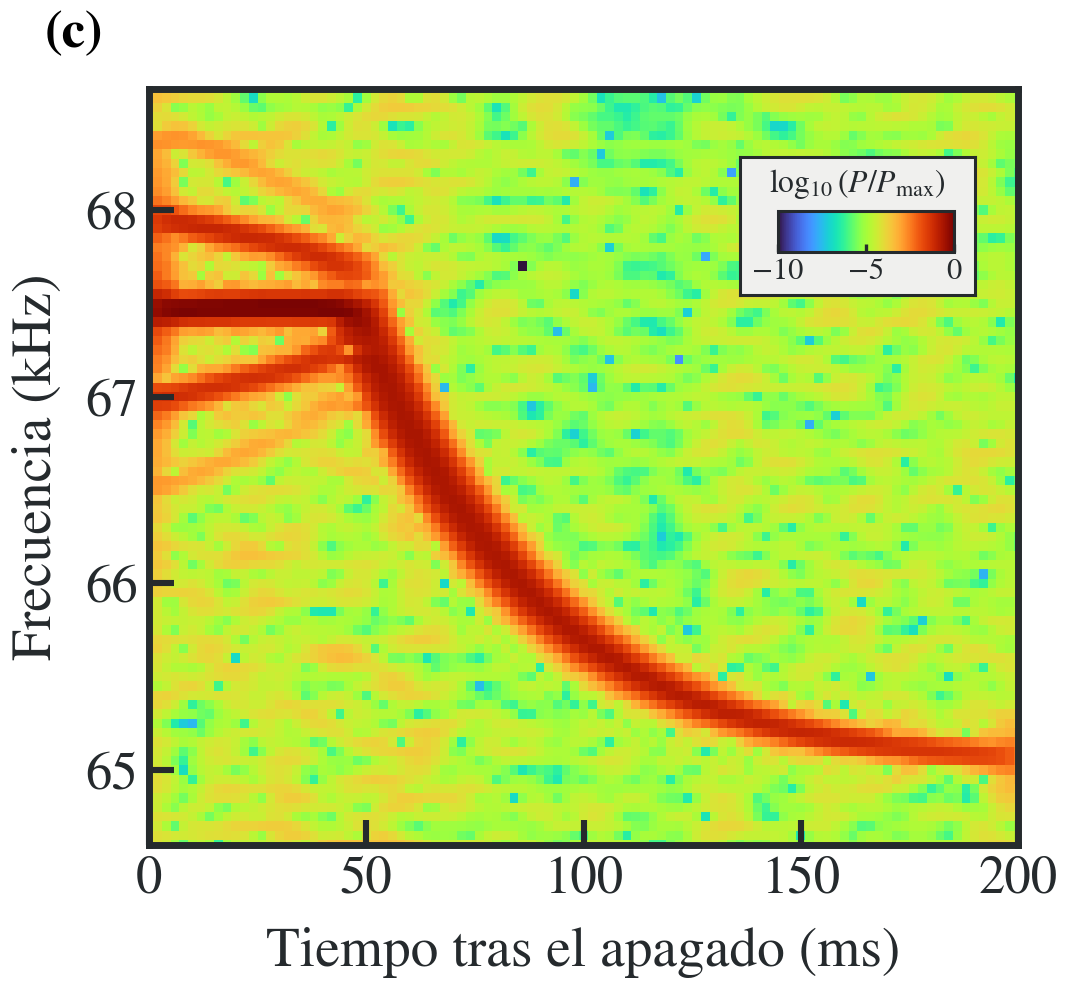

In [56]:
# Espectrograma independiente del mismo ringdown, en escala de potencia logarítmica relativa.
rd = ringdown_1625
# Reuse the original grid arrays for recording 1625; decibels / 10 = log10(P/Pmax).
report_spectrogram_data = {
    file.stem[-4:]: data for file, data in zip(files, ringdown_grid_data)
}["1625"]
log10_relative_power = np.asarray(report_spectrogram_data["decibels"]) / 10
# Keep the weaker upper branch with 0.25 kHz headroom.
visible_rows = np.max(report_spectrogram_data["decibels"], axis=1) >= -30
upper_branch_hz = report_spectrogram_data["frequency"][visible_rows][-1] * 1e3
spectrogram_ylim = (rd.spectrogram_frequency_limits[0], upper_branch_hz + .25e3)
with mpl.rc_context(PAPER_STYLE):
    fig_spectrogram_log, ax_spectrogram_log = plt.subplots(figsize=(92*MM, 92*MM))
    fig_spectrogram_log.subplots_adjust(left=.20, right=.80, bottom=.17, top=.95)
    fig_spectrogram_log.set_facecolor('none')
    ax_spectrogram_log.set_facecolor('#FFF8DF')
    ax_spectrogram_log.set_box_aspect(1/1.15)
    mesh_log = ax_spectrogram_log.pcolormesh(
        report_spectrogram_data["spectrogram_time"], report_spectrogram_data["frequency"],
        log10_relative_power, cmap="turbo", shading='auto', rasterized=True,
    )
    log10_colorbar_ticks = np.linspace(np.ceil(mesh_log.get_clim()[0]), 0, 3)
    ax_spectrogram_log.set(
        xlabel='Tiempo tras el apagado (ms)', ylabel='Frecuencia (kHz)',
        ylim=np.asarray(spectrogram_ylim)*1e-3,
        xlim=(0, report_spectrogram_data["end_time"]),
    )
    style_paper_axis(ax_spectrogram_log, image=True)
    ax_spectrogram_log.text(-.12, 1.04, '(c)', transform=ax_spectrogram_log.transAxes, ha='left', va='bottom', fontsize=9.5, fontweight='bold', clip_on=False, bbox={'facecolor':'white','edgecolor':'none','pad':1})
    ax_spectrogram_log.set_xticks([0, 50, 100, 150, 200])
    ax_spectrogram_log.set_yticks([65, 66, 67, 68])
    ax_spectrogram_log.tick_params(pad=2, direction='in')
    for spine in ax_spectrogram_log.spines.values():
        spine.set_visible(True)
        spine.set_color(INK)
        spine.set_linewidth(1.25)

    # Fondo opaco para que texto y escala queden legibles sobre el mapa de potencia.
    legend_ax = ax_spectrogram_log.inset_axes([.68, .727, .27, .183])
    legend_ax.set_facecolor('#F0F0EE')
    legend_ax.patch.set_alpha(1)
    legend_ax.set_xticks([])
    legend_ax.set_yticks([])
    legend_ax.set_zorder(10)
    for spine in legend_ax.spines.values():
        spine.set_visible(True)
        spine.set_color(INK)
        spine.set_linewidth(.55)
    legend_ax.text(.5, .80, r'$\log_{10}(P/P_{\max})$',
                   ha='center', va='center', fontsize=5.7, color=INK)
    cb_ax_log = legend_ax.inset_axes([.16, .31, .75, .30])
    cb_ax_log.set_facecolor('#F0F0EE')
    cb_log = fig_spectrogram_log.colorbar(
        mesh_log, cax=cb_ax_log, orientation='horizontal', ticks=log10_colorbar_ticks
    )
    cb_log.ax.tick_params(labelsize=5.5, length=1.4, width=.6, pad=1, colors=INK)
    cb_log.outline.set_edgecolor(INK)
    cb_log.outline.set_linewidth(.55)

    spectrogram_log_path = PAPER_OUTPUT_DIR/'ringdown_1625_spectrogram_logpower'
    fig_spectrogram_log.savefig(spectrogram_log_path.with_suffix('.pdf'), facecolor=fig_spectrogram_log.get_facecolor())
    fig_spectrogram_log.savefig(spectrogram_log_path.with_suffix('.png'), dpi=400, facecolor=fig_spectrogram_log.get_facecolor())
    plt.show()



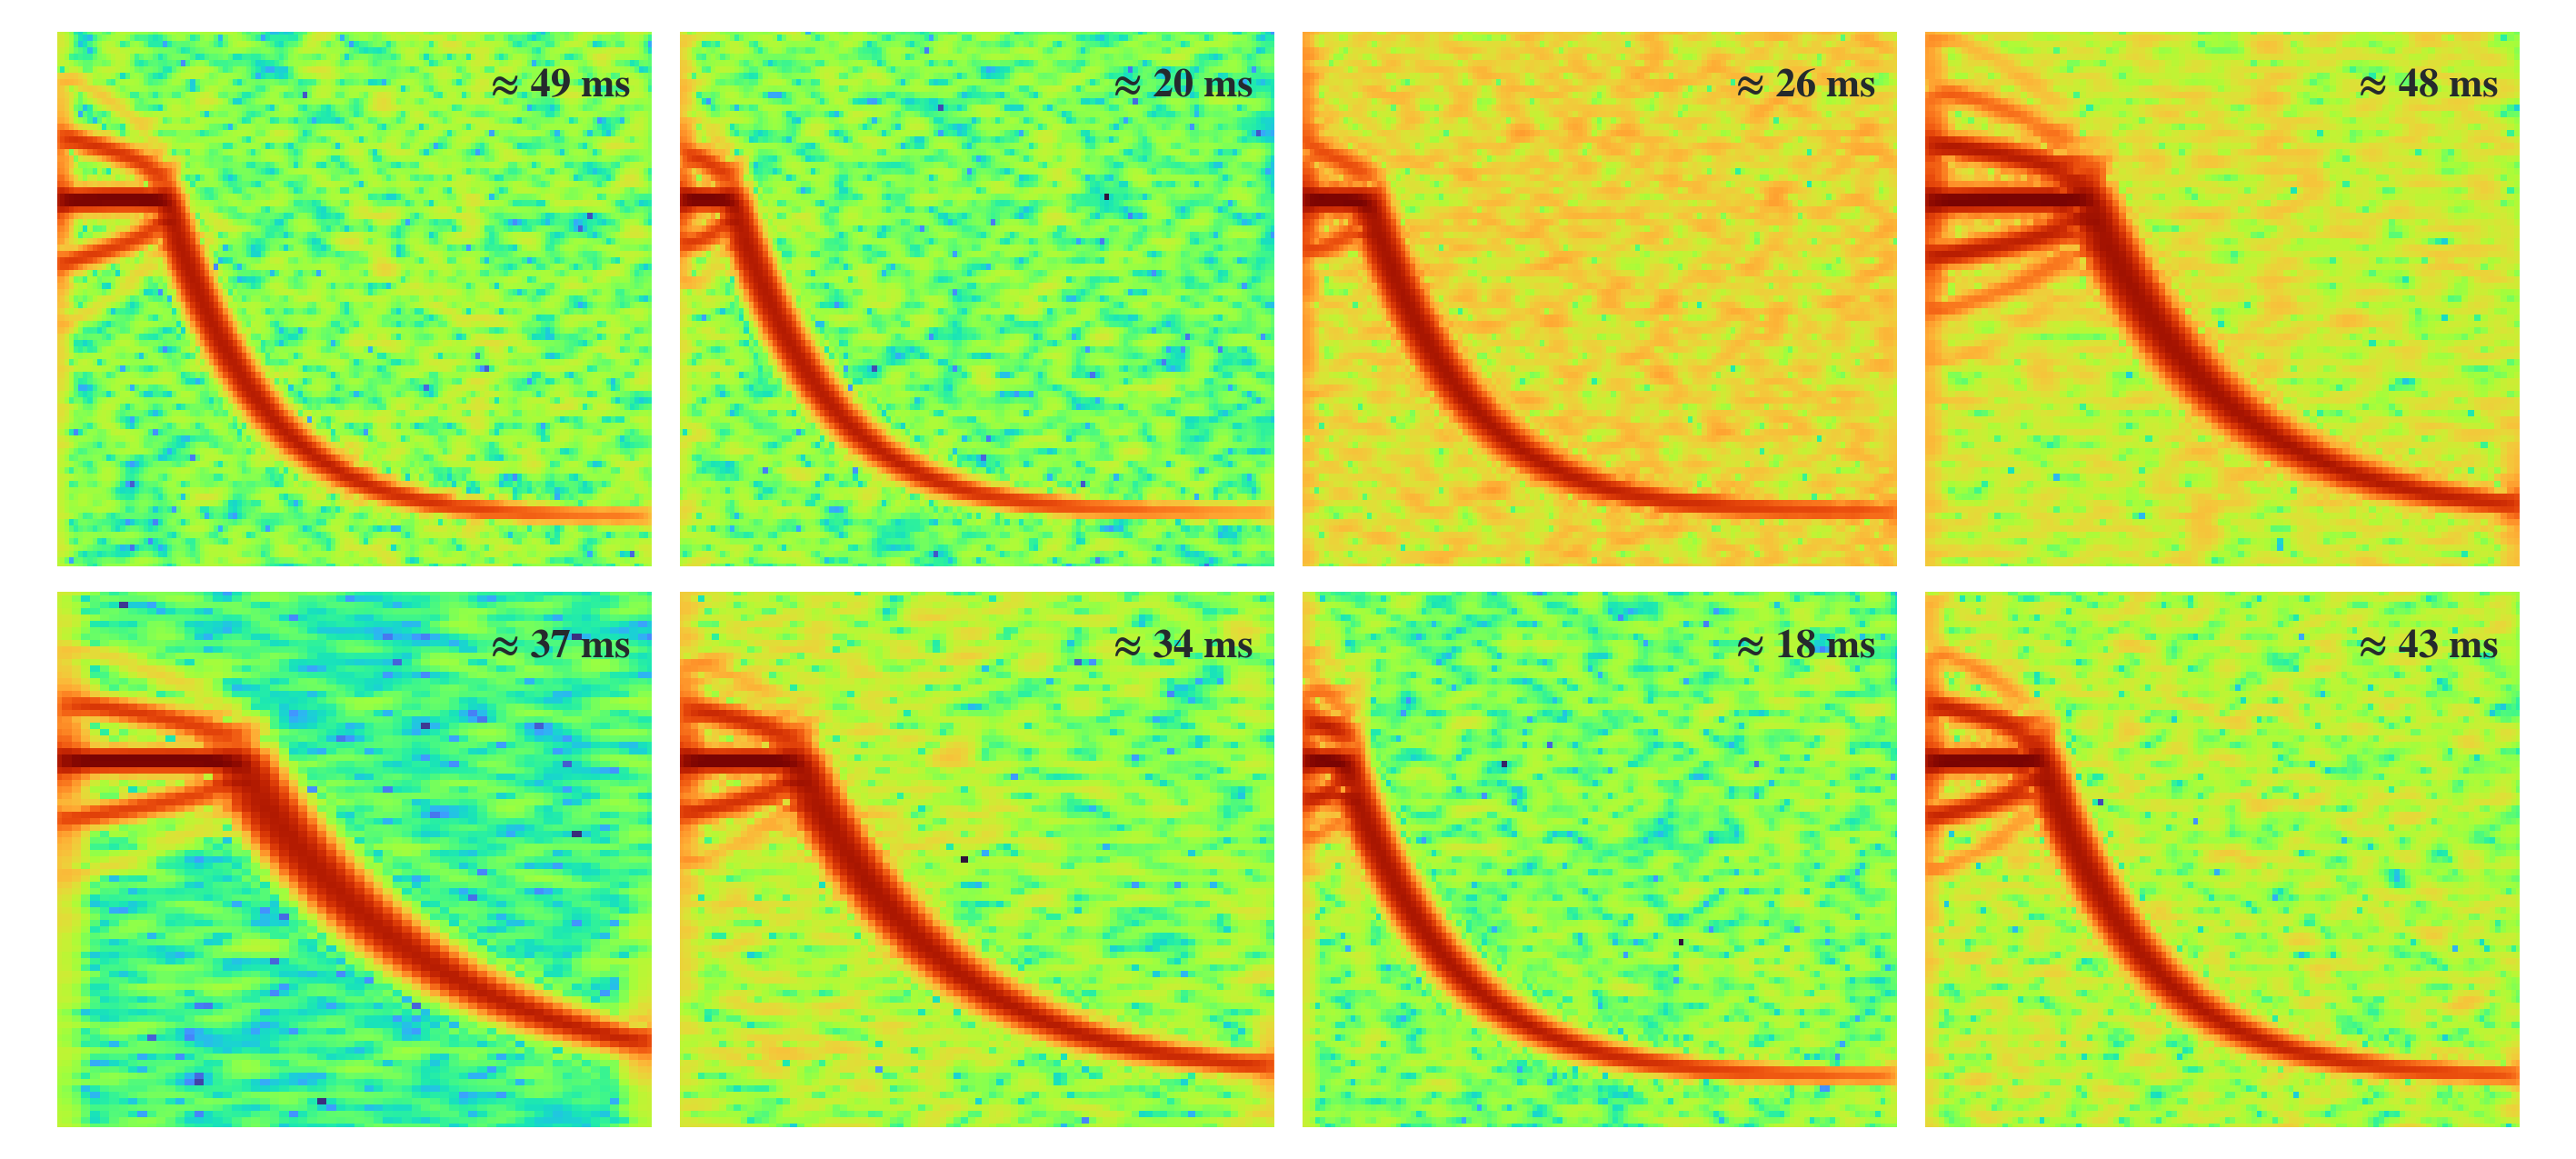

In [ ]:
# Mosaico de espectrogramas de ringdowns con duración de coherencia positiva.
# Reutiliza los arrays de la grilla de espectrogramas original.
coherence_positive_ms = {
    name: int(duration) for name, duration in coherencia_ms.items()
    if duration > 0
}
if len(files) != len(ringdown_grid_data):
    raise ValueError("The original ringdown grid files/data are not aligned")
coherence_grid_data = {
    file.stem[-4:]: data for file, data in zip(files, ringdown_grid_data)
}
missing_coherence_data = sorted(set(coherence_positive_ms) - set(coherence_grid_data))
if missing_coherence_data:
    raise KeyError(f"Missing original grid spectrograms: {missing_coherence_data}")
coherence_panel_order = ["1651", "1623", "1621", "1638", "1643", "1647", "1650", "1652"]
if len(coherence_panel_order) != 8 or not set(coherence_panel_order) <= set(coherence_positive_ms):
    raise ValueError("The explicit mosaic order must contain eight positive-duration records")
coherence_records = [
    (name, coherence_grid_data[name], coherence_positive_ms[name])
    for name in coherence_panel_order
]

coherence_ylim_khz = (64.6, 68.8)
coherence_cmap = "turbo"
coherence_tile_width_mm, coherence_tile_height_mm = 41.5, 37.35
coherence_fig_w_mm, coherence_fig_h_mm = 180, 81
coherence_cols, coherence_rows = 4, 2
coherence_x0_mm, coherence_y0_mm = 4.0, 2.25
coherence_xgap_mm, coherence_ygap_mm = 2.0, 1.8
with mpl.rc_context({**PAPER_STYLE, "savefig.bbox": None}):
    fig_coherence_mosaic = plt.figure(
        figsize=(coherence_fig_w_mm*MM, coherence_fig_h_mm*MM), facecolor="none"
    )
    coherence_axes = []
    for row in range(coherence_rows):
        y_mm = coherence_y0_mm + (coherence_rows - 1 - row) * (coherence_tile_height_mm + coherence_ygap_mm)
        for col in range(coherence_cols):
            x_mm = coherence_x0_mm + col * (coherence_tile_width_mm + coherence_xgap_mm)
            ax = fig_coherence_mosaic.add_axes([
                x_mm / coherence_fig_w_mm, y_mm / coherence_fig_h_mm,
                coherence_tile_width_mm / coherence_fig_w_mm,
                coherence_tile_height_mm / coherence_fig_h_mm,
            ])
            ax.set_box_aspect(.9)
            ax.set_facecolor("#FFF8DF")
            ax.set_axis_off()
            coherence_axes.append(ax)

    for ax, (record_id, data, duration_ms) in zip(coherence_axes, coherence_records):
        ax.pcolormesh(
            data["spectrogram_time"], data["frequency"], data["decibels"],
            shading="auto", cmap=coherence_cmap, rasterized=True,
        )
        ax.set_xlim(0, data["end_time"])
        ax.set_ylim(*coherence_ylim_khz)
        ax.text(.965, .93, f"≈ {duration_ms} ms", transform=ax.transAxes,
                ha="right", va="top", fontsize=8, fontweight="bold", color=INK)

    coherence_mosaic_path = PAPER_OUTPUT_DIR / "ringdown_coherence_spectrogram_mosaic"
    fig_coherence_mosaic.savefig(
        coherence_mosaic_path.with_suffix(".pdf"), facecolor=fig_coherence_mosaic.get_facecolor()
    )
    fig_coherence_mosaic.savefig(
        coherence_mosaic_path.with_suffix(".png"), dpi=400,
        facecolor=fig_coherence_mosaic.get_facecolor()
    )
    plt.show()
